**Integrantes**: *Marco Antonio Aragon Vivas, Juan David Reyes Burbano, Maria Paula Pinillo Olave, María José Suárez Toro, Laura Daniela Astudillo Ortega.*

# Proyecto 2. Sistema de detección, segmentación y clasificación de fracturas pélvicas mediante tomografía computarizada

**Sistema PENGWIN 2.5D multitarea**
> Uso académico: el modelo no ha sido validado clínicamente y no debe utilizarse para tomar decisiones quirúrgicas reales.

Las fracturas pélvicas pueden generar varios fragmentos óseos, por lo que identificarlos y medir su separación es una tarea importante para el análisis de estas lesiones. En este proyecto trabajamos con el dataset PENGWIN Task 1 (CT), presentado en el challenge MICCAI 2024, para desarrollar un sistema que permita analizar tomografías computarizadas de la pelvis.

El objetivo es detectar las regiones óseas (sacro, coxal izquierdo y coxal derecho), segmentar los fragmentos de cada región, clasificarlos según el hueso al que pertenecen y calcular la distancia entre los fragmentos secundarios y el fragmento principal en milímetros.

Para esto desarrollamos un modelo multitarea con una entrada 2.5D, que utiliza varios cortes de la tomografía para incorporar información de los cortes vecinos. Los resultados se integran en una aplicación web que permite visualizar las predicciones por corte y la reconstrucción tridimensional de los fragmentos.

---

## 0. Preparación

En esta sección importamos las librerías que vamos a utilizar durante el proyecto y definimos las rutas de las imágenes, las etiquetas y el caché. También establecemos los nombres y colores de las tres regiones óseas: sacro, coxal izquierdo y coxal derecho. Estos colores se mantienen en las visualizaciones del notebook y en la aplicación.

Antes de continuar, comprobamos que las imágenes y sus etiquetas estén disponibles y que ambos conjuntos contengan los mismos casos. La verificación encontró **100 casos con imagen y etiqueta**, por lo que podemos continuar con la preparación de los datos.

In [ ]:
import json
import os
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import SimpleITK as sitk
from matplotlib.patches import Rectangle
from scipy import ndimage

RAIZ = Path.cwd()
IMAGES = RAIZ / "data" / "raw" / "images"
LABELS = RAIZ / "data" / "raw" / "labels"
CACHE = RAIZ / "data" / "cache"

HUESO = {1: "sacro", 2: "coxal izquierdo", 3: "coxal derecho"}
COLOR = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a"}
FRAG = {1: "n_frag_sa", 2: "n_frag_lh", 3: "n_frag_rh"}
NEUTRO, GRIS, TINTA = "#52514e", "#c3c2b7", "#0b0b0b"

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "figure.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
})

casos = sorted(p.stem for p in IMAGES.glob("*.mha"))
assert casos and casos == sorted(p.stem for p in LABELS.glob("*.mha")), "Faltan datos: ver data/README.md"
print(f"{len(casos)} casos con imagen y etiqueta en {IMAGES.parent}")

100 casos con imagen y etiqueta en C:\Users\usuario\Desktop\Analitica carlos\proyecto\entregas\entrega final\data\raw


---

# Capítulo 1 · Exploración y preparación de los datos

Antes de diseñar ningún modelo hay que saber qué hay en los datos y convertirlos en algo que una red pueda leer: 31 GB de volúmenes en formatos, escalas y orientaciones distintos tienen que acabar en cortes 256×256, todos en la misma escala física y la misma orientación, que se lean al azar en milisegundos. El capítulo lo hace en cuatro pasos:

1. **Explorar los archivos y sus características** (1.1–1.7): qué trae cada archivo, qué significa su etiqueta y qué problemas esconde (ejes invertidos, escalas distintas, pacientes girados, cortes sin pelvis). Cada problema termina en una regla para el preprocesado.
2. **Construir el caché** (1.8–1.11): el preprocesado vive en `build_cache.py`; aquí se prueba sobre una muestra con las funciones del propio script y se verifica sobre los 100 casos.
3. **Definir la entrada del modelo** (1.12): tres ventanas de Hounsfield por corte y una pila de cortes vecinos.
4. **Analizar los datos y establecer las decisiones de diseño** (1.13–1.14): ocho análisis, cada uno con la decisión que justifica, y la partición por paciente.

## 1.1. Revisión de los archivos y sus cabeceras

Antes de procesar las tomografías, revisamos las cabeceras de las imágenes y sus máscaras para conocer sus dimensiones, el espaciado de los vóxeles y la orientación. Esta información es necesaria para comprobar que ambas estén alineadas y para calcular distancias en milímetros más adelante.

Para hacerlo, leemos las cabeceras sin cargar los vóxeles completos, lo que permite revisar los 100 casos de forma rápida.

In [ ]:
def cabecera(ruta: Path) -> dict:
    r = sitk.ImageFileReader()
    r.SetFileName(str(ruta))
    r.ReadImageInformation()
    return {
        **dict(zip(("nz", "ny", "nx"), r.GetSize()[::-1])),
        **dict(zip(("sz", "sy", "sx"), r.GetSpacing()[::-1])),
        "direccion": tuple(int(round(v)) for v in r.GetDirection()),
        "tipo": sitk.GetPixelIDValueAsString(r.GetPixelID()),
    }

def gb(carpeta: Path) -> float:
    return sum(p.stat().st_size for p in carpeta.glob("*.mha")) / 1024**3

t0 = time.perf_counter()
cab = pd.DataFrame.from_dict({c: cabecera(IMAGES / f"{c}.mha") for c in casos}, orient="index")
cab_lab = pd.DataFrame.from_dict({c: cabecera(LABELS / f"{c}.mha") for c in casos}, orient="index")
cab.index.name = "case_id"
t_cab = time.perf_counter() - t0

geometria = ["nz", "ny", "nx", "sz", "sy", "sx"]
misma = (np.isclose(cab[geometria].to_numpy(float), cab_lab[geometria].to_numpy(float), atol=1e-4).all(axis=1)
         & (cab.direccion == cab_lab.direccion).to_numpy())

print(f"{2 * len(casos)} cabeceras leídas en {t_cab:.2f} s, sin cargar un solo vóxel")
print(f"Imagen y etiqueta con la misma geometría: {misma.sum()} de {len(casos)} casos")
print(f"Tipo de dato en disco: imágenes {', '.join(cab.tipo.unique())} · etiquetas {', '.join(cab_lab.tipo.unique())}")
print(f"Tamaño en disco: imágenes {gb(IMAGES):.1f} GB · etiquetas {gb(LABELS):.1f} GB")
cab.drop(columns="tipo").head()

200 cabeceras leídas en 0.68 s, sin cargar un solo vóxel
Imagen y etiqueta con la misma geometría: 100 de 100 casos
Tipo de dato en disco: imágenes 32-bit signed integer, 16-bit signed integer · etiquetas 16-bit signed integer, 8-bit unsigned integer
Tamaño en disco: imágenes 18.8 GB · etiquetas 12.6 GB


,nz,ny,nx,sz,sy,sx,direccion
case_id,,,,,,,
001,401,512,512,0.8,0.781250,0.781250,"(1, 0, 0, 0, 1, 0, 0, 0, 1)"
002,337,276,413,0.8,0.824219,0.824219,"(-1, 0, 0, 0, -1, 0, 0, 0, 1)"
003,285,381,512,1.0,0.759766,0.759766,"(-1, 0, 0, 0, -1, 0, 0, 0, 1)"
004,224,254,386,1.0,0.843750,0.843750,"(-1, 0, 0, 0, -1, 0, 0, 0, 1)"
005,312,512,512,1.0,0.896484,0.896484,"(1, 0, 0, 0, 1, 0, 0, 0, 1)"


Los resultados muestran que los 100 casos tienen la misma geometría entre la imagen y su máscara. Sin embargo, las dimensiones, el espaciado y la orientación varían entre pacientes, por lo que será necesario tenerlos en cuenta durante el preprocesamiento. También observamos que las imágenes y las etiquetas utilizan distintos tipos de dato y ocupan aproximadamente 18,8 GB y 12,6 GB, respectivamente.

Los archivos están en formato `.mha` (MetaImage), aunque el enunciado menciona NIfTI. Esto no impide obtener el espaciado físico desde la cabecera, que es el dato necesario para las mediciones. Además, la comprobación realizada en esta sección se limita a las dimensiones, el espaciado y la dirección; el código de lectura de cada caso vuelve a verificar la geometría, incluido el origen.

## 1.2. Revisión de un caso

Para entender cómo están almacenadas las imágenes y sus etiquetas, cargamos el caso `001` y revisamos sus dimensiones, tipos de dato y valores de la máscara. También convertimos la imagen a `int16` y la etiqueta a `uint8` para reducir el espacio de memoria sin perder la información necesaria.

In [ ]:
caso = "001"
t0 = time.perf_counter()
img_sitk = sitk.ReadImage(str(IMAGES / f"{caso}.mha"))
lab_sitk = sitk.ReadImage(str(LABELS / f"{caso}.mha"))
t_lectura = time.perf_counter() - t0
img = sitk.GetArrayFromImage(img_sitk)               
lab = sitk.GetArrayFromImage(lab_sitk)

print(f"Leer imagen y etiqueta: {t_lectura:.1f} s")
print(f"imagen  : {img.dtype}, forma {img.shape} (z, y, x), {img.nbytes / 1024**2:,.0f} MB · HU de {img.min()} a {img.max()}")
print(f"etiqueta: {lab.dtype}, forma {lab.shape}, {lab.nbytes / 1024**2:,.0f} MB · valores {np.unique(lab).tolist()}")
img, lab = img.astype(np.int16), lab.astype(np.uint8)
print(f"\nEn int16 la imagen cabe entera (±32.767) y ocupa {img.nbytes / 1024**2:,.0f} MB; "
      f"en uint8 la etiqueta (0–255) ocupa {lab.nbytes / 1024**2:,.0f} MB.")

Leer imagen y etiqueta: 0.5 s
imagen  : int32, forma (401, 512, 512) (z, y, x), 401 MB · HU de -1023 a 2775


etiqueta: int16, forma (401, 512, 512), 200 MB · valores [0, 1, 11, 12, 21]

En int16 la imagen cabe entera (±32.767) y ocupa 200 MB; en uint8 la etiqueta (0–255) ocupa 100 MB.


La máscara utiliza valores numéricos para identificar los fragmentos óseos. Las etiquetas se organizan de la siguiente manera:

- **0:** fondo, no corresponde a ningún fragmento óseo.
- **1–10:** fragmentos del sacro.
- **11–20:** fragmentos del coxal izquierdo.
- **21–30:** fragmentos del coxal derecho.

Cada etiqueta permite identificar el hueso y el fragmento al que pertenece cada vóxel. Para separar esta información, utilizamos dos funciones: `a_hueso()` y `a_fragmento()`.

Para una etiqueta \(L > 0\), el macro-hueso se obtiene con:

$$
\text{Macro-hueso} = \left\lfloor \frac{L-1}{10} \right\rfloor + 1
$$

El índice del fragmento se calcula mediante:

$$
\text{Índice del fragmento} = (L-1) \bmod 10
$$

El índice del fragmento comienza en 0. El fondo se trata por separado, ya que las fórmulas solo se aplican a etiquetas mayores que cero. Así podemos identificar cada región anatómica y sus fragmentos sin modificar las etiquetas originales.

In [ ]:
def a_hueso(lab: np.ndarray) -> np.ndarray:
    lab = lab.astype(np.int16)
    return np.where(lab > 0, (lab - 1) // 10 + 1, 0).astype(np.uint8)

def a_fragmento(lab: np.ndarray) -> np.ndarray:
    lab = lab.astype(np.int16)
    return np.where(lab > 0, (lab - 1) % 10, 255).astype(np.uint8)

valores, voxeles = np.unique(lab, return_counts=True)
pd.DataFrame({"macro-hueso": [HUESO[h] for h in a_hueso(valores[1:])],
              "fragmento dentro del hueso": a_fragmento(valores[1:]),
              "vóxeles": voxeles[1:]},
             index=pd.Index(valores[1:], name="etiqueta"))

,macro-hueso,fragmento dentro del hueso,vóxeles
etiqueta,,,
1,sacro,0,458539
11,coxal izquierdo,0,762194
12,coxal izquierdo,1,63957
21,coxal derecho,0,844349


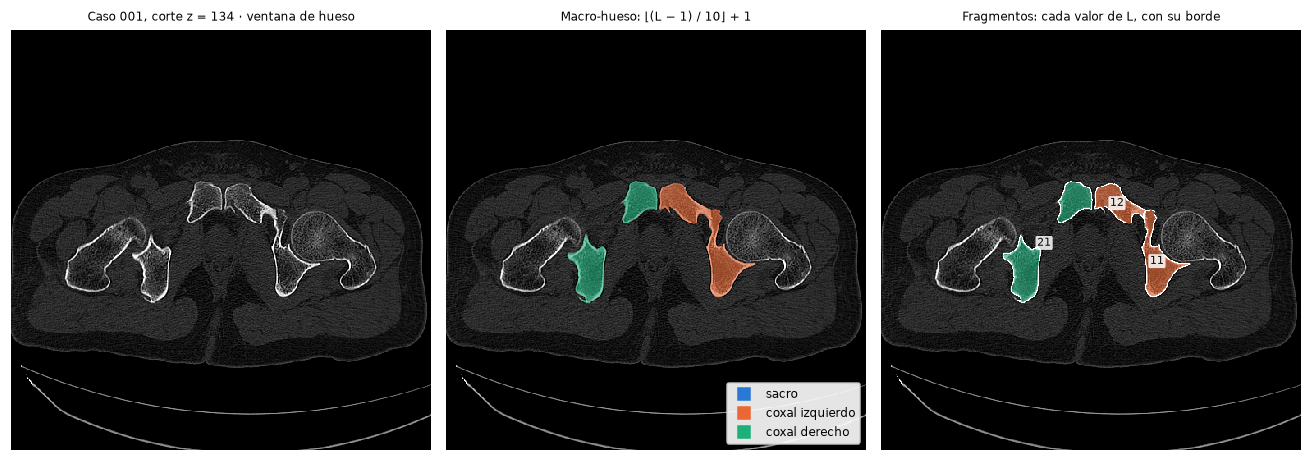

In [ ]:
def mostrar_corte(ax, hu2d, lab2d=None, titulo="", fragmentos=False):
    ax.imshow(np.clip(hu2d, -200, 1300), cmap="gray", interpolation="nearest")
    if lab2d is not None and lab2d.any():
        h = a_hueso(lab2d)
        capa = np.zeros((*lab2d.shape, 4))
        for k, c in COLOR.items():
            capa[h == k] = (*mcolors.to_rgb(c), 0.6)
        if fragmentos:
            borde = (ndimage.grey_dilation(lab2d, size=3) != ndimage.grey_erosion(lab2d, size=3)) & (lab2d > 0)
            capa[borde] = (1, 1, 1, 1)
            for v in np.unique(lab2d[lab2d > 0]):
                cy, cx = ndimage.center_of_mass(lab2d == v)
                ax.text(cx, cy, str(v), fontsize=7, ha="center", va="center", color=TINTA,
                        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
        ax.imshow(capa, interpolation="nearest")
    ax.set_title(titulo, fontsize=8)
    ax.axis("off")


def leyenda_huesos(destino, **kw):
    marcas = [plt.Line2D([], [], marker="s", ls="", ms=8, color=COLOR[k], label=HUESO[k]) for k in COLOR]
    destino.legend(handles=marcas, fontsize=8, **kw)

z = int(np.argmax((lab == 12).sum(axis=(1, 2))))
fig, axs = plt.subplots(1, 3, figsize=(12, 4.4))
mostrar_corte(axs[0], img[z], titulo=f"Caso {caso}, corte z = {z} · ventana de hueso")
mostrar_corte(axs[1], img[z], lab[z], titulo="Macro-hueso: ⌊(L − 1) / 10⌋ + 1")
mostrar_corte(axs[2], img[z], lab[z], titulo="Fragmentos: cada valor de L, con su borde", fragmentos=True)
leyenda_huesos(axs[1], loc="lower right", framealpha=0.9)
fig.tight_layout()
plt.show()

En el corte seleccionado del caso `001` se observa que el sacro tiene la etiqueta `1`, el coxal izquierdo presenta los fragmentos `11` y `12`, y el coxal derecho tiene la etiqueta `21`. En la figura central, los colores permiten distinguir las tres regiones anatómicas; en la última, los bordes y números muestran los fragmentos por separado.

Este ejemplo también permite ver que los fragmentos `11` y `12` del coxal izquierdo están muy próximos entre sí. Por eso es importante conservar las etiquetas individuales durante la segmentación.

Para el caché, guardaremos las imágenes en `int16` y las etiquetas en `uint8`. Como los valores de la máscara están entre `0` y `30`, podemos reducir su uso de memoria sin necesidad de guardar por separado las etiquetas de los macro-huesos y los fragmentos.

## 1.3. Orden de los ejes

Al trabajar con SimpleITK y NumPy, debemos tener en cuenta que los ejes se organizan en órdenes diferentes. SimpleITK devuelve el espaciado como `(x, y, z)`, mientras que el arreglo obtenido con NumPy tiene el orden `(z, y, x)`. Si usamos el espaciado sin ajustarlo, las distancias calculadas pueden ser incorrectas.

In [ ]:
sint = sitk.Image(5, 5, 5, sitk.sitkUInt8)            
sint.SetSpacing((1.0, 2.0, 4.0))                      
arr = sitk.GetArrayFromImage(sint)                    

principal = np.zeros(arr.shape, bool)
principal[1, 2, 2] = True
vecino_en_z = np.zeros(arr.shape, bool)
vecino_en_z[2, 2, 2] = True                          

def distancia_sintetica(espaciado):
    return ndimage.distance_transform_edt(~principal, sampling=espaciado)[vecino_en_z].min()


print(f"GetSpacing() = {sint.GetSpacing()}   → orden (x, y, z)")
print(f"array.shape  = {arr.shape}         → orden (z, y, x)\n")
print(f"Distancia con el espaciado invertido a (z, y, x)   : {distancia_sintetica(sint.GetSpacing()[::-1]):.1f} mm  ← correcta")
print(f"Distancia con el espaciado tal como lo da SimpleITK: {distancia_sintetica(sint.GetSpacing()):.1f} mm  ← error silencioso")

error = (cab.sx - cab.sz).abs() / cab.sz
print(f"\nEn este dataset, el error a lo largo de z llegaría al {error.max():.0%} (caso {error.idxmax()}); mediana {error.median():.0%}")

GetSpacing() = (1.0, 2.0, 4.0)   → orden (x, y, z)
array.shape  = (5, 5, 5)         → orden (z, y, x)

Distancia con el espaciado invertido a (z, y, x)   : 4.0 mm  ← correcta
Distancia con el espaciado tal como lo da SimpleITK: 1.0 mm  ← error silencioso

En este dataset, el error a lo largo de z llegaría al 53% (caso 039); mediana 14%


La prueba muestra que utilizar el orden incorrecto puede cambiar una distancia de 4 mm a 1 mm sin generar un error en el código. En los datos de PENGWIN, la diferencia en el eje z podría llegar al 53 %, con una mediana del 14 %.

Por eso, cuando trabajamos con arreglos de NumPy, utilizamos el espaciado en orden `(z, y, x)`, invirtiendo el valor obtenido con `GetSpacing()`. Después del remuestreo isotrópico a 1,5 mm, los tres ejes tienen el mismo espaciado, pero esta precaución sigue siendo necesaria al trabajar con los volúmenes originales.

## 1.4. Espaciado físico de las tomografías

Los vóxeles no tienen necesariamente el mismo tamaño en todos los pacientes. Por eso, revisamos el espaciado en los ejes x, y y z para conocer las diferencias entre las tomografías y definir una resolución común para el modelo.

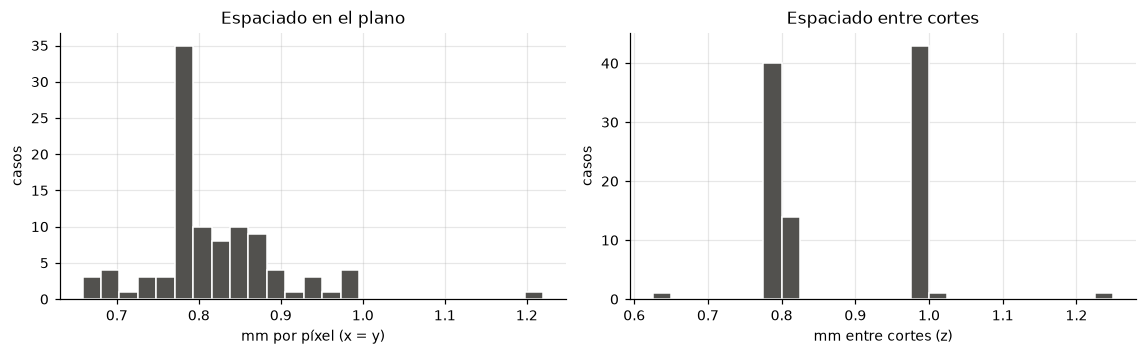

En el plano : 0.658 – 1.220 mm  (factor 1.85×)
Entre cortes: 0.625 – 1.250 mm  (factor 2.00×)
Volúmenes ya isotrópicos: 0 de 100
Cortes por volumen: 193 – 414 (mediana 326)


In [7]:
assert np.allclose(cab.sx, cab.sy), "se esperaban píxeles cuadrados"
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.3))
axs[0].hist(cab.sx, bins=25, color=NEUTRO, edgecolor="white")
axs[0].set(title="Espaciado en el plano", xlabel="mm por píxel (x = y)", ylabel="casos")
axs[1].hist(cab.sz, bins=25, color=NEUTRO, edgecolor="white")
axs[1].set(title="Espaciado entre cortes", xlabel="mm entre cortes (z)", ylabel="casos")
fig.tight_layout()
plt.show()

print(f"En el plano : {cab.sx.min():.3f} – {cab.sx.max():.3f} mm  (factor {cab.sx.max() / cab.sx.min():.2f}×)")
print(f"Entre cortes: {cab.sz.min():.3f} – {cab.sz.max():.3f} mm  (factor {cab.sz.max() / cab.sz.min():.2f}×)")
print(f"Volúmenes ya isotrópicos: {int(np.isclose(cab.sx, cab.sz, atol=1e-3).sum())} de {len(cab)}")
print(f"Cortes por volumen: {cab.nz.min()} – {cab.nz.max()} (mediana {int(cab.nz.median())})")

Los histogramas muestran que el espaciado varía entre pacientes, tanto dentro de cada corte como entre cortes. Ninguno de los volúmenes tiene el mismo espaciado en los tres ejes, por lo que necesitamos remuestrearlos a una resolución común.

Para elegir la resolución, comparamos cuánto espacio físico cubriría un recorte de 256 × 256 píxeles:

- **1,0 mm:** cubre 256 mm por lado, lo que puede dejar por fuera parte de la pelvis.
- **1,5 mm:** cubre 384 mm por lado y permite conservar la pelvis con margen.
- **2,0 mm:** cubre 512 mm por lado, pero reduce el detalle de los fragmentos pequeños.

Por estas razones, trabajamos con un espaciado de **1,5 mm en los tres ejes**, de modo que las imágenes tengan una escala física común y las distancias puedan calcularse correctamente.

In [8]:
sz, sy, sx = img_sitk.GetSpacing()[::-1]
hueso = lab > 0
ext = {e: (np.ptp(np.nonzero(hueso.any(axis=ejes))[0]) + 1) * s
       for e, ejes, s in (("z", (1, 2), sz), ("y", (0, 2), sy), ("x", (0, 1), sx))}
print(f"Hueso del caso {caso}: {ext['x']:.0f} mm de ancho (x) · {ext['y']:.0f} mm de fondo (y) · {ext['z']:.0f} mm de alto (z)")
print(f"Campo del recorte, 256 px × 1.5 mm = {256 * 1.5:.0f} mm → sobran {256 * 1.5 - max(ext['x'], ext['y']):.0f} mm en el eje más ancho")

Hueso del caso 001: 296 mm de ancho (x) · 162 mm de fondo (y) · 233 mm de alto (z)
Campo del recorte, 256 px × 1.5 mm = 384 mm → sobran 88 mm en el eje más ancho


En el caso 001, el hueso ocupa aproximadamente 296 mm de ancho, 162 mm de fondo y 233 mm de alto. El campo de 384 mm del recorte permite cubrir su ancho con un margen de 88 mm.

Sin embargo, este resultado corresponde a un solo paciente. Más adelante comprobaremos en otros casos si el recorte conserva todos los vóxeles de hueso.

## 1.5. Orientación de los volúmenes

Además del tamaño y el espaciado, las tomografías tienen una matriz de dirección que indica cómo están orientados sus ejes. Revisamos esta información para comprobar si todos los pacientes tienen la misma orientación antes de preparar los datos para el modelo.

In [9]:
identidad = (1, 0, 0, 0, 1, 0, 0, 0, 1)
for d, n in cab.direccion.value_counts().items():
    m = np.array(d, float).reshape(3, 3)
    print(f"{n:>3} casos · dirección {d} · diagonal {tuple(int(v) for v in np.diag(m))} · determinante {np.linalg.det(m):+.0f}")
girados = cab.index[cab.direccion.map(lambda d: d != identidad).to_numpy()]
girado = girados[0]

 66 casos · dirección (1, 0, 0, 0, 1, 0, 0, 0, 1) · diagonal (1, 1, 1) · determinante +1
 34 casos · dirección (-1, 0, 0, 0, -1, 0, 0, 0, 1) · diagonal (-1, -1, 1) · determinante +1


En el dataset encontramos dos orientaciones: 66 casos tienen la matriz identidad y 34 presentan los dos primeros ejes invertidos. Esto corresponde a una rotación de 180° en el plano, no a un reflejo, ya que el determinante sigue siendo +1.

Esta diferencia puede observarse en las imágenes de dos pacientes: aunque representan la misma anatomía, la pelvis aparece girada en uno de ellos. Por eso, es necesario revisar la orientación antes de preparar los datos para el modelo.

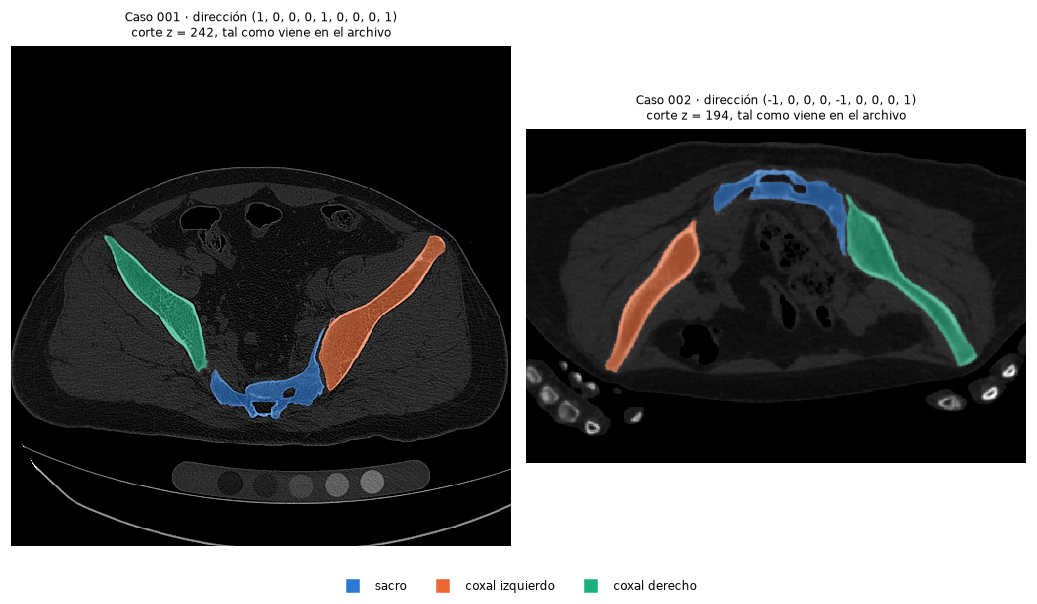

In [ ]:
def z_tres_huesos(lab3d: np.ndarray) -> int:
    presentes = [((lab3d >= 10 * k - 9) & (lab3d <= 10 * k)).any(axis=(1, 2)) for k in (1, 2, 3)]
    return int(np.median(np.nonzero(np.all(presentes, axis=0))[0]))

img_g = sitk.GetArrayFromImage(sitk.ReadImage(str(IMAGES / f"{girado}.mha")))
lab_g = sitk.GetArrayFromImage(sitk.ReadImage(str(LABELS / f"{girado}.mha")))

fig, axs = plt.subplots(1, 2, figsize=(9.5, 5.2))
for ax, (c, im, lb) in zip(axs, [(caso, img, lab), (girado, img_g, lab_g)]):
    zc = z_tres_huesos(lb)
    mostrar_corte(ax, im[zc], lb[zc], titulo=f"Caso {c} · dirección {cab.direccion[c]}\ncorte z = {zc}, tal como viene en el archivo")
leyenda_huesos(fig, loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()
del img_g, lab_g

En el caso 001, el sacro aparece en la parte inferior de la imagen y el coxal izquierdo a la derecha. En el otro caso, la pelvis está girada 180°. Si no corregimos esta diferencia, el modelo tendría que aprender las mismas estructuras en dos orientaciones distintas, lo que podría dificultar la clasificación entre el coxal izquierdo y el derecho.

Por esta razón, orientamos los volúmenes a la convención LPS mediante `sitk.DICOMOrient` antes del remuestreo. Esta operación ajusta la orientación de los ejes sin interpolar los valores de las imágenes ni modificar las etiquetas de las máscaras.

## 1.6. Distribución del hueso a lo largo de los cortes

Las tomografías incluyen zonas por encima y por debajo de la pelvis donde no hay hueso anotado. Para entender qué parte del volumen contiene información útil, revisamos el área de hueso presente en cada corte del caso `001`.

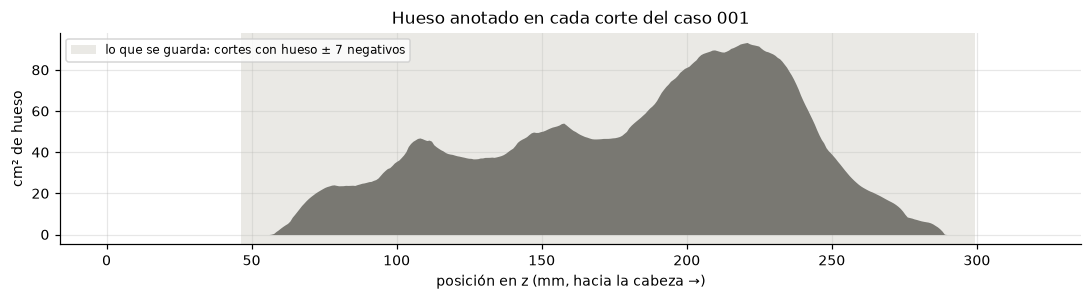

Cortes con hueso: 291 de 401 (73%), de z = 57 a 289 mm


In [ ]:
area = (lab > 0).sum(axis=(1, 2)) * sy * sx / 100      
z_mm = np.arange(len(area)) * sz
con = np.nonzero(area)[0]
margen = 7 * 1.5                                    

fig, ax = plt.subplots(figsize=(10, 2.8))
ax.fill_between(z_mm, area, color=NEUTRO, lw=0)
ax.axvspan(z_mm[con[0]] - margen, z_mm[con[-1]] + margen, color=GRIS, alpha=0.35, lw=0,
           label="lo que se guarda: cortes con hueso ± 7 negativos")
ax.set(title=f"Hueso anotado en cada corte del caso {caso}", xlabel="posición en z (mm, hacia la cabeza →)",
       ylabel="cm² de hueso")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

print(f"Cortes con hueso: {con.size} de {len(area)} ({con.size / len(area):.0%}), de z = {z_mm[con[0]]:.0f} a {z_mm[con[-1]]:.0f} mm")

En el caso `001`, encontramos hueso anotado en 291 de los 401 cortes (73 %), entre los 57 y 289 mm de posición en el eje z. Los cortes alejados de este rango no contienen hueso anotado, mientras que los que están cerca de sus extremos pueden servir como ejemplos negativos para que el modelo aprenda dónde termina la región ósea.

Por eso, conservamos los cortes que contienen hueso y siete cortes adicionales a cada lado como negativos. Con el espaciado de 1,5 mm, estos representan aproximadamente 10,5 mm por lado.

## 1.7. Preparación del caché

Como el entrenamiento utiliza muchos cortes de diferentes pacientes, leer y procesar los archivos originales en cada época aumentaría el tiempo de ejecución. Por eso, preparamos un caché que permite acceder a los datos más rápido y evita repetir el preprocesamiento.

Guardaremos las imágenes en formato `.npy` con intensidades HU en `int16` y las etiquetas en `uint8`, manteniendo sus valores originales. También crearemos un índice con información de cada corte y un informe por paciente para registrar la geometría y las verificaciones realizadas. Las ventanas HU se aplicarán durante la carga de los datos, sin necesidad de modificar el caché.

## 1.8. Construcción del caché

El script `build_cache.py` prepara los datos siguiendo los pasos definidos en las secciones anteriores:

| Paso | Proceso | Propósito |
|---|---|---|
| 1 | Comprobar la geometría de la imagen y su etiqueta | Verificar que estén alineadas. |
| 2 | Orientar los volúmenes a LPS | Unificar la orientación de los pacientes. |
| 3 | Remuestrear a 1,5 mm isotrópicos | Trabajar con una escala física común. |
| 4 | Recortar a 256 × 256 píxeles | Mantener la región de interés. |
| 5 | Seleccionar los cortes con hueso y siete cortes negativos a cada lado | Conservar la pelvis y ejemplos cercanos sin hueso. |
| 6 | Guardar las imágenes, etiquetas e índice | Facilitar el acceso durante el entrenamiento. |
| 7 | Verificar los datos procesados | Detectar pérdida de vóxeles óseos o cambios inesperados en las etiquetas. |

El recorte se centra en la mediana de las coordenadas de los vóxeles con intensidad superior a 200 HU. Utilizamos la mediana para reducir la influencia de valores aislados y el centro se calcula a partir de la imagen, sin consultar la máscara, para que el procedimiento también pueda utilizarse con tomografías sin etiquetas.

## 1.9. Prueba del preprocesamiento

Antes de procesar los 100 casos, probamos las funciones de `build_cache.py` con una muestra de seis pacientes. Seleccionamos casos con distintos espaciados, incluyendo los valores extremos, el caso 001 y un paciente con orientación diferente. Así podemos revisar cómo se comporta el preprocesamiento en distintas condiciones.

In [ ]:
sys.path.insert(0, str(RAIZ))
sys.dont_write_bytecode = True                        
import build_cache as bc                            
muestra = sorted({cab.sx.idxmin(), cab.sx.idxmax(), cab.sz.idxmin(), cab.sz.idxmax(), caso, girado})
cab.loc[muestra, ["nz", "ny", "nx", "sz", "sx", "direccion"]].assign(girado=lambda t: t.index.isin(girados))

,nz,ny,nx,sz,sx,direccion,girado
case_id,,,,,,,
001,401,512,512,0.800000,0.781250,"(1, 0, 0, 0, 1, 0, 0, 0, 1)",False
002,337,276,413,0.800000,0.824219,"(-1, 0, 0, 0, -1, 0, 0, 0, 1)",True
039,392,154,322,0.800000,1.220000,"(1, 0, 0, 0, 1, 0, 0, 0, 1)",False
044,409,183,370,0.625000,0.873047,"(-1, 0, 0, 0, -1, 0, 0, 0, 1)",True
047,193,512,512,1.250005,0.748047,"(1, 0, 0, 0, 1, 0, 0, 0, 1)",False
086,265,283,512,1.000000,0.658203,"(-1, 0, 0, 0, -1, 0, 0, 0, 1)",True


### Ejemplo de preprocesamiento

Tomamos el caso 002 para observar cómo cambia la tomografía durante las tres etapas principales del preprocesamiento: orientación a LPS, remuestreo a 1,5 mm y recorte a 256 × 256 píxeles. En cada etapa usamos el mismo nivel anatómico para comparar los cambios.

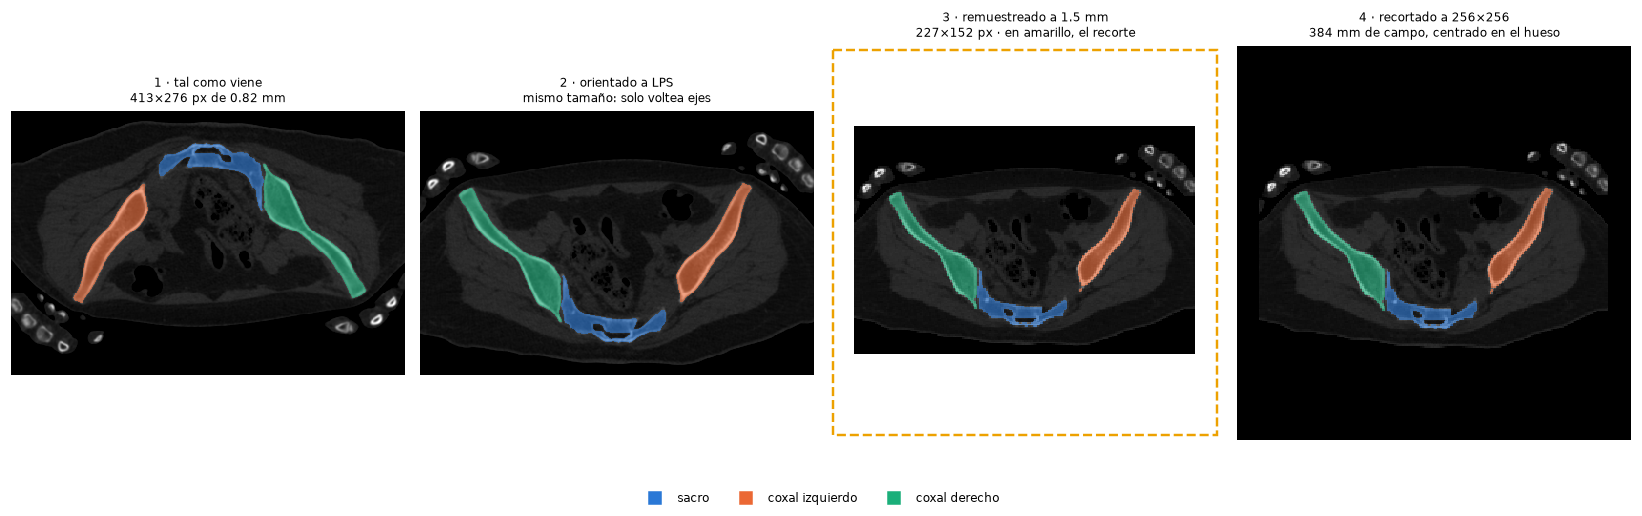

Caso 002: (337, 276, 413) vóxeles (z, y, x) → remuestreado (180, 152, 227) → recortado (180, 256, 256) · centro del hueso en (fila, columna) = (78, 114)


In [ ]:
img0 = sitk.ReadImage(str(IMAGES / f"{girado}.mha"))
lab0 = sitk.ReadImage(str(LABELS / f"{girado}.mha"))
img1, lab1 = bc.orientar(img0), bc.orientar(lab0)                                        
img2, lab2 = bc.remuestrear(img1, es_etiqueta=False), bc.remuestrear(lab1, es_etiqueta=True)  
hu2 = sitk.GetArrayFromImage(img2).astype(np.int16)
et2 = sitk.GetArrayFromImage(lab2).astype(np.uint8)
centro = bc.centro_hueso(hu2)                                                             
hu3, et3 = bc.recortar(hu2, centro, bc.AIR_HU), bc.recortar(et2, centro, 0)

z0 = z_tres_huesos(sitk.GetArrayViewFromImage(lab0))
z_iso = int(round(z0 * img0.GetSpacing()[2] / bc.ISO_MM))
corte = lambda imagen: np.array(sitk.GetArrayViewFromImage(imagen)[z0])

pasos = [
    (corte(img0), corte(lab0), f"1 · tal como viene\n{img0.GetSize()[0]}×{img0.GetSize()[1]} px de {img0.GetSpacing()[0]:.2f} mm"),
    (corte(img1), corte(lab1), "2 · orientado a LPS\nmismo tamaño: solo voltea ejes"),
    (hu2[z_iso], et2[z_iso], f"3 · remuestreado a 1.5 mm\n{hu2.shape[2]}×{hu2.shape[1]} px · en amarillo, el recorte"),
    (hu3[z_iso], et3[z_iso], "4 · recortado a 256×256\n384 mm de campo, centrado en el hueso"),
]
fig, axs = plt.subplots(1, 4, figsize=(15, 4.6))
for ax, (h, l, titulo) in zip(axs, pasos):
    mostrar_corte(ax, h, l, titulo=titulo)
cy, cx = centro
mitad = bc.CROP_PX // 2
axs[2].add_patch(Rectangle((cx - mitad - 0.5, cy - mitad - 0.5), bc.CROP_PX, bc.CROP_PX,
                           fill=False, ec="#eda100", lw=1.6, ls="--"))
axs[2].set_xlim(min(-0.5, cx - mitad - 0.5) - 3, max(hu2.shape[2], cx + mitad) + 3)
axs[2].set_ylim(max(hu2.shape[1], cy + mitad) + 3, min(-0.5, cy - mitad - 0.5) - 3)
leyenda_huesos(fig, loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

print(f"Caso {girado}: {img0.GetSize()[::-1]} vóxeles (z, y, x) → remuestreado {hu2.shape} → recortado {hu3.shape}"
      f" · centro del hueso en (fila, columna) = {centro}")

La figura muestra el efecto de cada paso. Primero, la orientación a LPS corrige la posición de la pelvis sin cambiar el tamaño del volumen. Después, el remuestreo establece un espaciado de 1,5 mm por vóxel. Por último, el recorte fija las dimensiones en 256 × 256 píxeles y centra la imagen en el hueso.

En el caso 002, el volumen remuestreado es más estrecho que el campo de 384 mm del recorte, por lo que algunas zonas quedan fuera de la imagen original. Estas áreas se rellenan con −1024 HU en la imagen y con 0 en la máscara, sin introducir nuevas etiquetas óseas.

### Prueba con seis pacientes

Aplicamos `preparar_caso()` a los seis pacientes seleccionados para comprobar que el preprocesamiento funcione con distintas dimensiones, espaciados y orientaciones. También revisamos las dimensiones finales, los vóxeles de hueso perdidos, los cambios en las etiquetas y el tiempo de procesamiento.

In [14]:
procesados = {}
for c in muestra:
    t0 = time.perf_counter()
    hu_c, lab_c, info = bc.preparar_caso(c)
    info["segundos"] = time.perf_counter() - t0
    procesados[c] = (hu_c, lab_c, info)

inf_muestra = pd.DataFrame([p[2] for p in procesados.values()]).set_index("case_id")
inf_muestra[["sz", "sx", "nz_iso", "ny_iso", "nx_iso", "hueso_mm_y", "hueso_mm_x", "vox_perdidos",
             "etiquetas_perdidas", "etiquetas_inventadas", "cortes_hueso", "z0", "z1", "segundos"]].round(2)

,sz,sx,nz_iso,ny_iso,nx_iso,hueso_mm_y,hueso_mm_x,vox_perdidos,etiquetas_perdidas,etiquetas_inventadas,cortes_hueso,z0,z1,segundos
case_id,,,,,,,,,,,,,,
001,0.80,0.78,214,267,267,162.0,295.5,0,0,0,155,31,200,1.07
002,0.80,0.82,180,152,227,142.5,277.5,0,0,0,137,14,165,0.47
039,0.80,1.22,209,125,262,151.5,306.0,0,0,0,141,30,185,0.31
044,0.62,0.87,170,107,215,154.5,274.5,0,0,0,145,2,161,0.32
047,1.25,0.75,161,255,255,150.0,283.5,0,0,0,137,4,155,0.58
086,1.00,0.66,177,124,225,136.5,271.5,0,0,0,149,2,165,0.50


In [ ]:
def lado_coxal_izquierdo(lab3d: np.ndarray) -> tuple[int, int]:
    h = a_hueso(lab3d)
    izq, der = (h == 2).sum(axis=1), (h == 3).sum(axis=1)
    ambos = (izq.sum(axis=1) > 0) & (der.sum(axis=1) > 0)
    columnas = np.arange(lab3d.shape[2])
    x_izq = (izq[ambos] * columnas).sum(axis=1) / izq[ambos].sum(axis=1)
    x_der = (der[ambos] * columnas).sum(axis=1) / der[ambos].sum(axis=1)
    return int((x_izq > x_der).sum()), int(ambos.sum())

lados = []
for c in muestra:
    antes, n_antes = lado_coxal_izquierdo(sitk.GetArrayFromImage(sitk.ReadImage(str(LABELS / f"{c}.mha"))))
    despues, n_despues = lado_coxal_izquierdo(procesados[c][1])
    lados.append({"caso": c, "girado": c in girados,
                  "tal como viene": f"{antes / n_antes:.0%} de {n_antes} cortes",
                  "tras el script": f"{despues / n_despues:.0%} de {n_despues} cortes"})

print(f"Vóxeles de hueso perdidos en el recorte : {int(inf_muestra.vox_perdidos.sum())}")
print(f"Etiquetas perdidas / inventadas         : {int(inf_muestra.etiquetas_perdidas.sum())} / {int(inf_muestra.etiquetas_inventadas.sum())}")
print(f"Extensión ósea máxima en el plano       : {inf_muestra[['hueso_mm_y', 'hueso_mm_x']].max().max():.0f} mm de {bc.CROP_PX * bc.ISO_MM:.0f}")
print("\n¿Cae el coxal izquierdo a la derecha de la imagen, como manda la convención radiológica?")
pd.DataFrame(lados).set_index("caso")

Vóxeles de hueso perdidos en el recorte : 0
Etiquetas perdidas / inventadas         : 0 / 0
Extensión ósea máxima en el plano       : 306 mm de 384

¿Cae el coxal izquierdo a la derecha de la imagen, como manda la convención radiológica?


,girado,tal como viene,tras el script
caso,,,
001,False,100% de 266 cortes,100% de 142 cortes
002,True,0% de 233 cortes,100% de 124 cortes
039,False,100% de 230 cortes,100% de 123 cortes
044,True,0% de 338 cortes,100% de 141 cortes
047,False,100% de 154 cortes,100% de 129 cortes
086,True,0% de 211 cortes,100% de 141 cortes


En los seis casos no se perdieron vóxeles de hueso ni se encontraron etiquetas perdidas o inventadas. La extensión ósea máxima en el plano fue de 306 mm, dentro de los 384 mm disponibles en el recorte.

También comprobamos la orientación de los coxales. Antes del preprocesamiento, los tres casos que venían girados tenían el coxal izquierdo al lado contrario del esperado. Después de aplicar el proceso, el coxal izquierdo quedó a la derecha de la imagen en todos los cortes revisados.

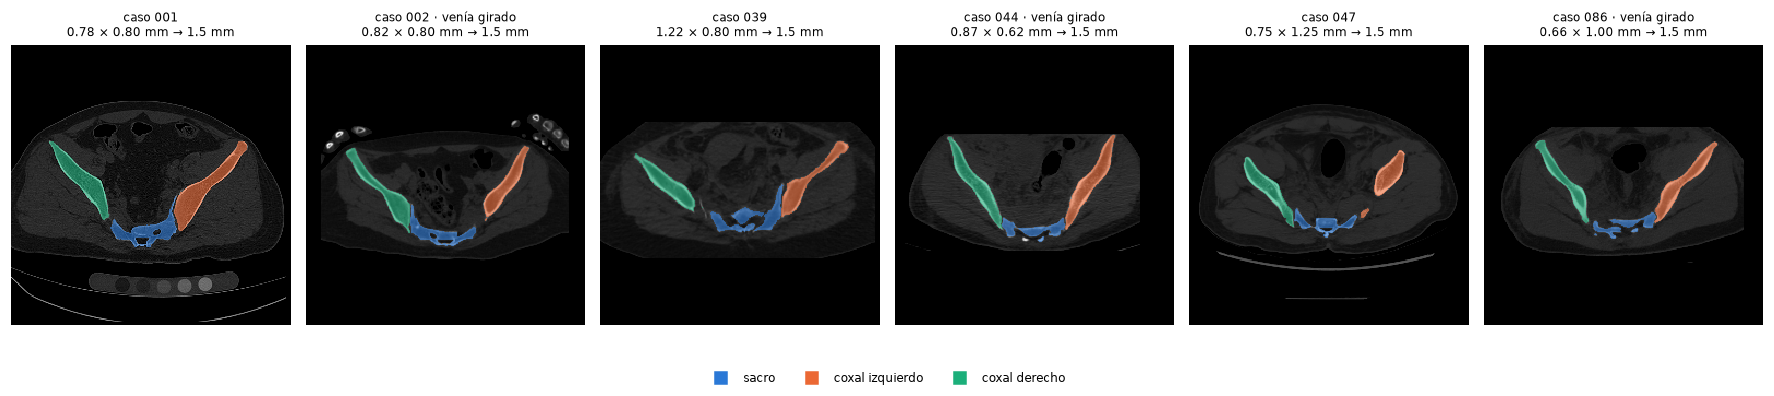

In [16]:
fig, axs = plt.subplots(1, len(muestra), figsize=(2.7 * len(muestra), 3.5))
for ax, c in zip(axs, muestra):
    hu_c, lab_c, info = procesados[c]
    zc = z_tres_huesos(lab_c)
    mostrar_corte(ax, hu_c[zc], lab_c[zc],
                  titulo=f"caso {c}{' · venía girado' if c in girados else ''}\n{info['sx']:.2f} × {info['sz']:.2f} mm → 1.5 mm")
leyenda_huesos(fig, loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

Después del preprocesamiento, los seis pacientes tienen la misma orientación y un espaciado de 1,5 mm. Aunque las tomografías originales tenían dimensiones y resoluciones diferentes, las imágenes quedan centradas en la pelvis y con un tamaño común de 256 × 256 píxeles.

En la figura se puede comparar la anatomía de cada paciente después de aplicar los mismos pasos de procesamiento. Los colores permiten distinguir el sacro, el coxal izquierdo y el coxal derecho.

### Selección de cortes

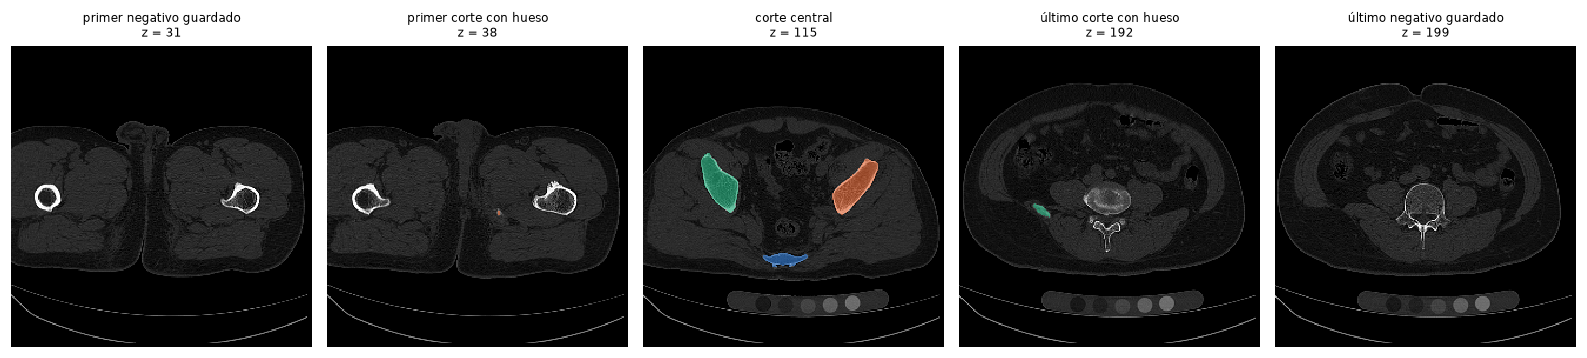

Caso 001: 214 cortes tras remuestrear · 155 con hueso · se guardan 169 (z = 31 … 199)


In [17]:
hu_c, lab_c, info = procesados[caso]
z_hueso = np.nonzero(lab_c.reshape(len(lab_c), -1).any(axis=1))[0]
seleccion = {"primer negativo guardado": info["z0"], "primer corte con hueso": z_hueso[0],
             "corte central": int(np.median(z_hueso)), "último corte con hueso": z_hueso[-1],
             "último negativo guardado": info["z1"] - 1}

fig, axs = plt.subplots(1, 5, figsize=(14.5, 3.4))
for ax, (rotulo, zc) in zip(axs, seleccion.items()):
    mostrar_corte(ax, hu_c[zc], lab_c[zc], titulo=f"{rotulo}\nz = {zc}")
fig.tight_layout()
plt.show()
print(f"Caso {caso}: {len(lab_c)} cortes tras remuestrear · {info['cortes_hueso']} con hueso · "
      f"se guardan {info['z1'] - info['z0']} (z = {info['z0']} … {info['z1'] - 1})")

Los primeros y últimos cortes muestran por qué conservamos algunos cortes sin hueso junto a los que sí lo contienen. En los extremos, el hueso aparece o desaparece gradualmente, por lo que estos cortes ayudan al modelo a reconocer dónde empieza y termina la región ósea.

En el caso 001, se guardan 169 de los 214 cortes remuestreados: los que contienen hueso y siete cortes adicionales a cada lado.

### Organización de los datos procesados

Después de preparar los casos, reunimos los cortes seleccionados en dos arreglos: uno para las imágenes y otro para las etiquetas. También construimos un índice con información de cada corte, como los huesos presentes y la cantidad de fragmentos, que utilizaremos más adelante durante el entrenamiento.

In [18]:
mini_hu = np.concatenate([p[0][p[2]["z0"]:p[2]["z1"]] for p in procesados.values()])
mini_lab = np.concatenate([p[1][p[2]["z0"]:p[2]["z1"]] for p in procesados.values()])
mini_indice = pd.DataFrame([{"case_id": c, "z": z, **bc.estadisticas_corte(p[1][z])}
                            for c, p in procesados.items() for z in range(p[2]["z0"], p[2]["z1"])])
assert len(mini_indice) == len(mini_hu) == len(mini_lab)
print(f"slices_hu: {mini_hu.shape} {mini_hu.dtype} · labels: {mini_lab.shape} {mini_lab.dtype} · índice: {len(mini_indice)} filas\n")
mini_indice.iloc[3:12]

slices_hu: (948, 256, 256) int16 · labels: (948, 256, 256) uint8 · índice: 948 filas



,case_id,z,n_frag_sa,n_frag_lh,n_frag_rh,bones_present,n_frag_total,n_regions,area_bone_px,has_bone
3,001,34,0,0,0,0,0,0,0,0
4,001,35,0,0,0,0,0,0,0,0
5,001,36,0,0,0,0,0,0,0,0
6,001,37,0,0,0,0,0,0,0,0
7,001,38,0,1,0,2,1,1,8,1
8,001,39,0,1,0,2,1,1,65,1
9,001,40,0,2,0,2,2,1,142,1
10,001,41,0,2,0,2,2,1,211,1
11,001,42,0,2,1,6,3,2,291,1


Cada fila del índice corresponde a un corte y mantiene el mismo orden que los arreglos de imágenes y etiquetas. Las columnas `n_frag_sa`, `n_frag_lh` y `n_frag_rh` indican cuántos fragmentos de cada hueso aparecen en el corte.

La columna `bones_present` codifica los huesos presentes mediante una máscara de bits: el bit 0 corresponde al sacro, el bit 1 al coxal izquierdo y el bit 2 al coxal derecho. Por su parte, `has_bone` permite distinguir los cortes que contienen hueso de los negativos.

En esta muestra se obtuvieron 948 cortes, con sus imágenes en `int16` y sus etiquetas en `uint8`. El índice también permite identificar la transición entre los cortes negativos y aquellos donde empiezan a aparecer fragmentos óseos.

### Estimación del procesamiento completo

Con los tiempos y el tamaño de los datos obtenidos en la muestra, estimamos cuánto tardaría el procesamiento de los 100 pacientes y cuánto espacio ocuparían los arreglos antes de guardarse en disco.

In [ ]:
s_caso = inf_muestra.segundos.mean()
mb_caso = (mini_hu.nbytes + mini_lab.nbytes) / len(muestra) / 1024**2
cortes_caso = len(mini_indice) / len(muestra)
print(f"Por caso, en la muestra: {s_caso:.1f} s · {cortes_caso:.0f} cortes · {mb_caso:.0f} MB")
print(f"Estimación para los {len(casos)}: ~{s_caso * len(casos) / 60:.1f} min · ~{cortes_caso * len(casos):,.0f} cortes · "
      f"~{mb_caso * len(casos) / 1024:.1f} GB que se acumulan en memoria antes de escribirse")
print(f"Volúmenes que hay que leer: {gb(IMAGES) + gb(LABELS):.1f} GB")

del img, lab, img_sitk, lab_sitk, hueso, img0, lab0, img1, lab1, img2, lab2, hu2, et2, hu3, et3
del procesados, mini_hu, mini_lab, hu_c, lab_c

Por caso, en la muestra: 0.5 s · 158 cortes · 30 MB
Estimación para los 100: ~0.9 min · ~15,800 cortes · ~2.9 GB que se acumulan en memoria antes de escribirse
Volúmenes que hay que leer: 31.4 GB


Según la muestra, el procesamiento tardaría aproximadamente 0,9 minutos para los 100 casos y generaría cerca de 15.800 cortes, con un tamaño acumulado de unos 2,9 GB para las imágenes y etiquetas. Los archivos originales ocupan 31,4 GB, por lo que preparar el caché permite trabajar después con datos organizados para acceder a los cortes sin tener que procesar nuevamente cada tomografía.

## 1.10. Ejecución del preprocesamiento

Después de comprobar las funciones con la muestra, ejecutamos el procesamiento completo de los 100 pacientes mediante `build_cache.py`. De esta forma, separamos la exploración y las pruebas del procesamiento por lotes.

Esta decisión tiene varias ventajas:

- **Memoria:** los arreglos de imágenes y etiquetas ocupan aproximadamente 3 GB, por lo que conviene liberar la memoria al terminar el proceso.
- **Tiempo de ejecución:** el caché se construye una sola vez y puede reutilizarse en las siguientes ejecuciones del notebook.
- **Reproducibilidad:** el procesamiento se ejecuta con el comando `python build_cache.py`, sin depender del orden en que se ejecuten las celdas.
- **Protección de los datos:** el script no reemplaza un caché existente, a menos que se utilice la opción `--force`.

Así, el notebook se utiliza para analizar los datos y comprobar las decisiones, mientras que el script se encarga de aplicar el preprocesamiento a todos los pacientes.

## 1.11 · El caché completo

Se construye una vez, desde una terminal en la carpeta del proyecto. Tarda alrededor de minuto y medio:

```
python build_cache.py            # no toca un caché que ya exista
python build_cache.py --force    # lo reconstruye
```

| Archivo | Contenido |
|---|---|
| `data/cache/slices_hu.npy` | `int16` · (N, 256, 256) · unidades Hounsfield crudas |
| `data/cache/labels.npy` | `uint8` · (N, 256, 256) · codificación PENGWIN 0–30 |
| `data/cache/index.parquet` | Una fila por corte, en el mismo orden que los `.npy` |
| `data/cache/casos.csv` | Una fila por caso: geometría original y verificaciones |

Si el caché no existe, la celda siguiente lanza el script, como proceso aparte, por las razones de la sección 1.10, para que el notebook pueda ejecutarse de principio a fin. Después lo abre **mapeado en memoria**: `mmap_mode="r"` no carga los 3 GB, el sistema operativo lee cada corte cuando se pide.

In [ ]:
if not (CACHE / "slices_hu.npy").exists():
    print("No hay caché: se construye con build_cache.py en un proceso aparte (unos minutos)…")
    r = subprocess.run([sys.executable, str(RAIZ / "build_cache.py")], capture_output=True, text=True,
                       encoding="utf-8", env={**os.environ, "PYTHONIOENCODING": "utf-8"})
    print(r.stdout[-1500:] + r.stderr[-1500:])
    r.check_returncode()

hu_cache = np.load(CACHE / "slices_hu.npy", mmap_mode="r")
lab_cache = np.load(CACHE / "labels.npy", mmap_mode="r")
indice = pd.read_parquet(CACHE / "index.parquet")
informe = pd.read_csv(CACHE / "casos.csv", dtype={"case_id": str}).set_index("case_id")
assert (indice.row == np.arange(len(indice))).all() and len(indice) == len(hu_cache) == len(lab_cache)

con_hueso = int(indice.has_bone.sum())
print(f"slices_hu.npy : {hu_cache.shape} {hu_cache.dtype} · {hu_cache.nbytes / 1024**3:.2f} GB")
print(f"labels.npy    : {lab_cache.shape} {lab_cache.dtype} · {lab_cache.nbytes / 1024**3:.2f} GB")
print(f"index.parquet : {len(indice):,} cortes de {indice.case_id.nunique()} casos · {con_hueso:,} con hueso "
      f"y {len(indice) - con_hueso:,} negativos ({1 - con_hueso / len(indice):.1%})")

slices_hu.npy : (15626, 256, 256) int16 · 1.91 GB
labels.npy    : (15626, 256, 256) uint8 · 0.95 GB
index.parquet : 15,626 cortes de 100 casos · 14,238 con hueso y 1,388 negativos (8.9%)


### Verificación de los 100 casos

Después de construir el caché, revisamos los resultados de los 100 pacientes para comprobar que el preprocesamiento no haya generado problemas. Verificamos que las imágenes y sus máscaras tengan la misma geometría, que no se hayan perdido vóxeles de hueso ni etiquetas y que el recorte sea suficiente para conservar toda la región ósea.

In [21]:
lado = bc.CROP_PX * bc.ISO_MM
extension = informe[["hueso_mm_y", "hueso_mm_x"]].max(axis=1)
guardados = informe.z1 - informe.z0
verificacion = pd.Series({
    "casos procesados": f"{len(informe)} de {len(casos)}",
    "imagen y etiqueta con la misma geometría": f"{int(informe.geometria_ok.sum())} de {len(informe)}",
    "vóxeles de hueso perdidos en el recorte": f"{int(informe.vox_perdidos.sum())} de {int(informe.vox_hueso.sum()):,}",
    "etiquetas perdidas / inventadas": f"{int(informe.etiquetas_perdidas.sum())} / {int(informe.etiquetas_inventadas.sum())}",
    "extensión ósea máxima en el plano": f"{extension.max():.0f} mm de {lado:.0f} mm (caso {extension.idxmax()})",
    "cortes guardados por caso": f"{guardados.min()} – {guardados.max()}",
}, name="resultado")

assert len(informe) == len(casos) and informe.geometria_ok.all() and informe.vox_perdidos.sum() == 0
assert (informe.etiquetas_perdidas + informe.etiquetas_inventadas).sum() == 0 and extension.max() < lado
assert guardados.sum() == len(indice)
verificacion.to_frame()

,resultado
casos procesados,100 de 100
imagen y etiqueta con la misma geometría,100 de 100
vóxeles de hueso perdidos en el recorte,"0 de 23,139,258"
etiquetas perdidas / inventadas,0 / 0
extensión ósea máxima en el plano,318 mm de 384 mm (caso 066)
cortes guardados por caso,136 – 186


### Verificación de la orientación

También comprobamos que la orientación de los coxales sea correcta en todo el caché, no solamente en los seis pacientes de la prueba inicial. Para esto, revisamos los cortes donde aparecen el coxal izquierdo y el derecho y verificamos que el izquierdo quede a la derecha de la imagen.

In [22]:
filas_2cox = indice.row.to_numpy()[(indice.bones_present.to_numpy() & 0b110) == 0b110]
a_la_derecha = total = 0
for i in range(0, len(filas_2cox), 2048):
    a, n = lado_coxal_izquierdo(np.asarray(lab_cache[filas_2cox[i:i + 2048]]))
    a_la_derecha, total = a_la_derecha + a, total + n

print(f"Casos que venían girados            : {int((informe.direccion != str(identidad)).sum())} de {len(informe)}")
print(f"Cortes del caché con los dos coxales: {total:,}")
print(f"Coxal izquierdo a la derecha        : {a_la_derecha:,} ({a_la_derecha / total:.1%})")
assert a_la_derecha == total

Casos que venían girados            : 34 de 100
Cortes del caché con los dos coxales: 13,088
Coxal izquierdo a la derecha        : 13,088 (100.0%)


### Tiempo de lectura del caché

Por último, comparamos el tiempo necesario para leer un lote de 32 cortes desde el caché con el tiempo que tarda en prepararse un caso desde los archivos originales. Esto nos permite comprobar si guardar los datos procesados facilita su uso durante el entrenamiento.

In [23]:
rng = np.random.default_rng(0)
lote = np.sort(rng.choice(len(indice), size=32, replace=False))
t0 = time.perf_counter()
x, y = np.asarray(hu_cache[lote]), np.asarray(lab_cache[lote])
t_lote = time.perf_counter() - t0
print(f"Un lote de 32 cortes al azar desde el caché: {1000 * t_lote:.1f} ms")
print(f"Un solo caso preparado desde los .mha      : {s_caso:.1f} s")

Un lote de 32 cortes al azar desde el caché: 2.5 ms
Un solo caso preparado desde los .mha      : 0.5 s


Los resultados muestran que los 100 casos se procesaron correctamente. Las imágenes y las máscaras tienen la misma geometría, no se perdieron vóxeles de hueso ni etiquetas y la extensión ósea máxima fue de 318 mm, dentro de los 384 mm disponibles en el recorte. Por tanto, el recorte fue suficiente para conservar el hueso en todos los casos.

En cuanto a la orientación, 34 pacientes venían girados y, después del preprocesamiento, los 13.088 cortes que contienen ambos coxales cumplen con la condición esperada: el coxal izquierdo queda a la derecha de la imagen.

Finalmente, leer un lote de 32 cortes desde el caché tardó 2,5 ms, mientras que preparar un caso desde los archivos originales tomó 0,5 segundos. Esto muestra que el caché permite acceder a los datos mucho más rápido y evita repetir el preprocesamiento durante las siguientes etapas del proyecto.

## 1.12. La entrada del modelo: tres ventanas y una pila de cortes

El caché guarda las tomografías con sus intensidades originales en unidades Hounsfield (HU). Antes de pasarlas al modelo, transformamos cada corte en tres canales, usando una ventana diferente para cada uno. Así podemos resaltar tanto el hueso como los tejidos blandos y el contorno general del cuerpo.

Cada ventana recorta los valores HU a un rango y los normaliza entre 0 y 1:

$$
x_k = \frac{\operatorname{clip}(HU, lo_k, hi_k)-lo_k}{hi_k-lo_k}
$$

| Canal | Ventana (HU) | Qué permite observar |
|---|---|---|
| 0 · Hueso | [-200, 1300] | Los bordes y la estructura ósea. |
| 1 · Tejido blando | [-150, 250] | Los músculos y los tejidos alrededor de los huesos. |
| 2 · Amplia | [-1000, 2000] | La pelvis y el contorno general del cuerpo. |

Usar tres canales también permite adaptar la entrada a las redes preentrenadas con ImageNet, que normalmente reciben imágenes RGB de tres canales.

### Entrada 2.5D

Además de los tres canales del corte central, utilizamos cortes vecinos del mismo paciente. Esto le da al modelo información sobre cómo cambia la anatomía entre cortes, sin tener que procesar el volumen completo con una red 3D.

Probamos tres opciones para seleccionar los vecinos:

- **Tres cortes:** z−1, z y z+1, separados 1,5 mm.
- **Tres cortes más distantes:** z−2, z y z+2, separados 3 mm respecto al central.
- **Cinco cortes:** z−4, z−2, z, z+2 y z+4, que abarcan 12 mm entre los extremos.

Cada corte aporta tres canales, por lo que la entrada con cinco cortes tiene 15 canales. Los objetivos de clasificación, detección y segmentación se calculan únicamente a partir de la etiqueta del corte central; los vecinos aportan contexto.

En los extremos de cada volumen, cuando no hay suficientes cortes vecinos, se repite el corte disponible más cercano. Además, los vecinos siempre pertenecen al mismo paciente para evitar mezclar anatomías diferentes.

La opción de cinco cortes, guardada en la configuración `DESP`, es la que utilizamos en el resto del notebook. En el análisis 1.13 se estudian las diferencias entre las opciones y en la sección 3.3 se comparan durante el entrenamiento.

Por último, `cargar_corte()` reúne la entrada y los objetivos que necesita el modelo: las clases de los huesos presentes, las cajas de detección y las máscaras de segmentación.

In [ ]:
VENTANAS = ((-200, 1300), (-150, 250), (-1000, 2000))
VARIANTES_25D = {"±1": (-1, 0, 1), "±2": (-2, 0, 2), "5 cortes": (-4, -2, 0, 2, 4)}
DESP = VARIANTES_25D["5 cortes"]

def ventanear(hu: np.ndarray) -> np.ndarray:
    return np.stack([(np.clip(hu, lo, hi).astype(np.float32) - lo) / (hi - lo) for lo, hi in VENTANAS], axis=-3)

def cajas_por_region(lab2d: np.ndarray) -> dict[int, tuple[int, int, int, int]]:
    h = a_hueso(lab2d)
    cajas = {}
    for k in (1, 2, 3):
        m = h == k
        filas, columnas = np.nonzero(m.any(axis=1))[0], np.nonzero(m.any(axis=0))[0]
        if filas.size:
            cajas[k] = (int(columnas[0]), int(filas[0]), int(columnas[-1]) + 1, int(filas[-1]) + 1)
    return cajas

assert all((np.diff(g.row) == 1).all() and (np.diff(g.z) == 1).all() for _, g in indice.groupby("case_id")), \
    "los cortes de cada paciente tienen que estar seguidos y en orden de z"
_ini = indice.groupby("case_id").row.transform("min").to_numpy()
_fin = indice.groupby("case_id").row.transform("max").to_numpy()

def orden_central(desplazamientos) -> tuple:
    return (0, *[d for d in desplazamientos if d != 0])

def filas_vecinas(fila: int, desplazamientos=DESP) -> np.ndarray:
    return np.clip(fila + np.array(orden_central(desplazamientos)), _ini[fila], _fin[fila])

def entrada_25d(fila: int, desplazamientos=DESP) -> np.ndarray:
    return ventanear(np.asarray(hu_cache[filas_vecinas(fila, desplazamientos)])).reshape(-1, bc.CROP_PX, bc.CROP_PX)

def cargar_corte(fila: int, desplazamientos=DESP) -> dict:
    hu, lab = np.asarray(hu_cache[fila]), np.asarray(lab_cache[fila])
    presentes = int(indice.bones_present.iat[fila])
    return {
        "entrada": entrada_25d(fila, desplazamientos),
        "huesos": np.array([(presentes >> i) & 1 for i in range(3)], np.float32),
        "cajas": cajas_por_region(lab),
        "hueso": a_hueso(lab), "fragmento": a_fragmento(lab),
        "hu": hu, "etiqueta": lab,
    }

candidatas = indice.row[(indice.n_regions == 3) & (indice.n_frag_total >= 5)]
fila = int(candidatas.iat[len(candidatas) // 2])
ej = cargar_corte(fila)
assert ej["entrada"].shape == (3 * len(DESP), 256, 256) and np.array_equal(ej["entrada"][:3], ventanear(ej["hu"]))
primera = int(_ini[fila])
assert (filas_vecinas(primera, (-2, 0, 2)) == [primera, primera, primera + 2]).all()
print(f"Fila {fila} del caché: caso {indice.case_id.iat[fila]}, z = {indice.z.iat[fila]} · pila {DESP}: filas "
      f"{filas_vecinas(fila).tolist()}")
print(f"  entrada   : {ej['entrada'].dtype} {ej['entrada'].shape} · rango [{ej['entrada'].min():.2f}, {ej['entrada'].max():.2f}]"
      f" · los canales 0–2 son las tres ventanas del corte central")
print(f"  huesos    : {ej['huesos']}  (sacro, coxal izquierdo, coxal derecho)")
print(f"  cajas     : {ej['cajas']}")
print(f"  hueso     : {ej['hueso'].dtype} {ej['hueso'].shape} · valores {np.unique(ej['hueso']).tolist()}")
print(f"  fragmento : {ej['fragmento'].dtype} {ej['fragmento'].shape} · valores {np.unique(ej['fragmento']).tolist()} (255 = fondo)")
print(f"  en la primera fila de su paciente, la pila ±2 es {filas_vecinas(primera, (-2, 0, 2)).tolist()}: el vecino de abajo "
      f"no existe y se repite el central")

Fila 6941 del caché: caso 045, z = 133 · pila (-4, -2, 0, 2, 4): filas [6941, 6937, 6939, 6943, 6945]
  entrada   : float32 (15, 256, 256) · rango [0.00, 1.00] · los canales 0–2 son las tres ventanas del corte central
  huesos    : [1. 1. 1.]  (sacro, coxal izquierdo, coxal derecho)
  cajas     : {1: (94, 127, 167, 164), 2: (158, 75, 206, 167), 3: (37, 122, 107, 176)}
  hueso     : uint8 (256, 256) · valores [0, 1, 2, 3]
  fragmento : uint8 (256, 256) · valores [0, 1, 2, 255] (255 = fondo)
  en la primera fila de su paciente, la pila ±2 es [6814, 6814, 6816]: el vecino de abajo no existe y se repite el central


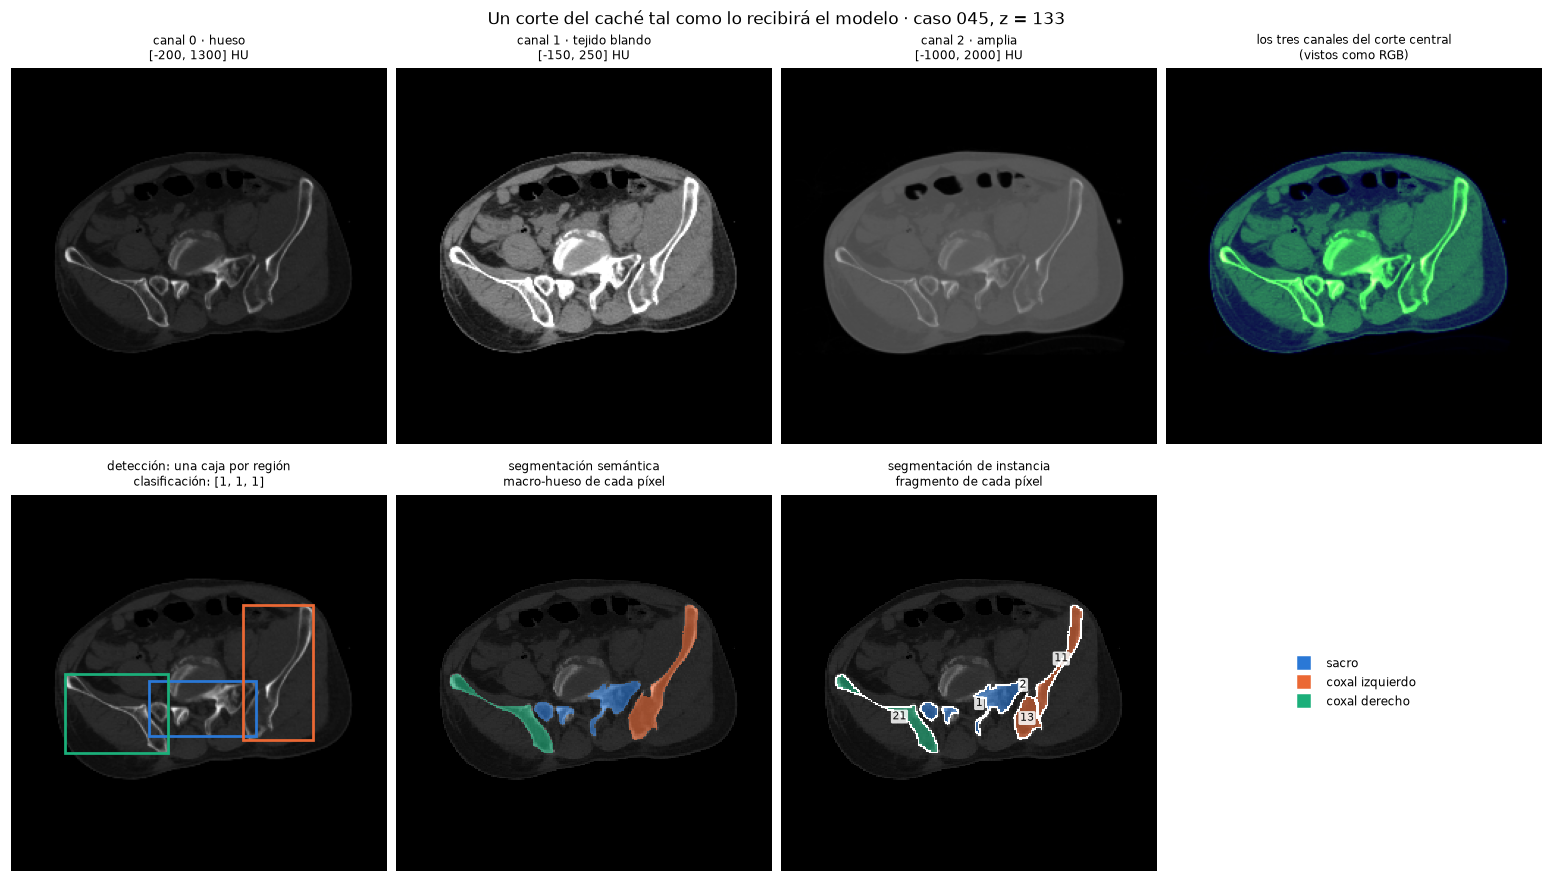

In [25]:
fig = plt.figure(figsize=(14, 8), layout="constrained")
for k, nombre in enumerate(("hueso", "tejido blando", "amplia")):
    ax = fig.add_subplot(2, 4, k + 1)
    ax.imshow(ej["entrada"][k], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"canal {k} · {nombre}\n[{VENTANAS[k][0]}, {VENTANAS[k][1]}] HU", fontsize=8)
    ax.axis("off")
ax = fig.add_subplot(2, 4, 4)
ax.imshow(np.moveaxis(ej["entrada"][:3], 0, -1))
ax.set_title("los tres canales del corte central\n(vistos como RGB)", fontsize=8)
ax.axis("off")

ax = fig.add_subplot(2, 4, 5)
ax.imshow(np.clip(ej["hu"], -200, 1300), cmap="gray")
for k, (x0, y0, x1, y1) in ej["cajas"].items():
    ax.add_patch(Rectangle((x0 - 0.5, y0 - 0.5), x1 - x0, y1 - y0, fill=False, ec=COLOR[k], lw=1.8))
ax.set_title(f"detección: una caja por región\nclasificación: {ej['huesos'].astype(int).tolist()}", fontsize=8)
ax.axis("off")
mostrar_corte(fig.add_subplot(2, 4, 6), ej["hu"], ej["etiqueta"], titulo="segmentación semántica\nmacro-hueso de cada píxel")
mostrar_corte(fig.add_subplot(2, 4, 7), ej["hu"], ej["etiqueta"], titulo="segmentación de instancia\nfragmento de cada píxel",
              fragmentos=True)
ax = fig.add_subplot(2, 4, 8)
ax.axis("off")
leyenda_huesos(ax, loc="center", frameon=False)
fig.suptitle(f"Un corte del caché tal como lo recibirá el modelo · caso {indice.case_id.iat[fila]}, z = {indice.z.iat[fila]}")
plt.show()

En la figura se observa cómo cambia el contraste al utilizar las tres ventanas. La de hueso permite distinguir mejor las estructuras óseas, la de tejido blando muestra el contexto anatómico y la amplia conserva una vista general de la pelvis.

En la parte inferior aparecen los objetivos que se obtienen de la máscara original: la clasificación indica qué huesos están presentes, la detección marca una caja para cada región y la segmentación identifica los huesos y sus fragmentos píxel a píxel.

Para este ejemplo, la entrada tiene 15 canales y los tres huesos están presentes. Esto confirma que `cargar_corte()` prepara tanto la información de entrada como los objetivos del corte central.

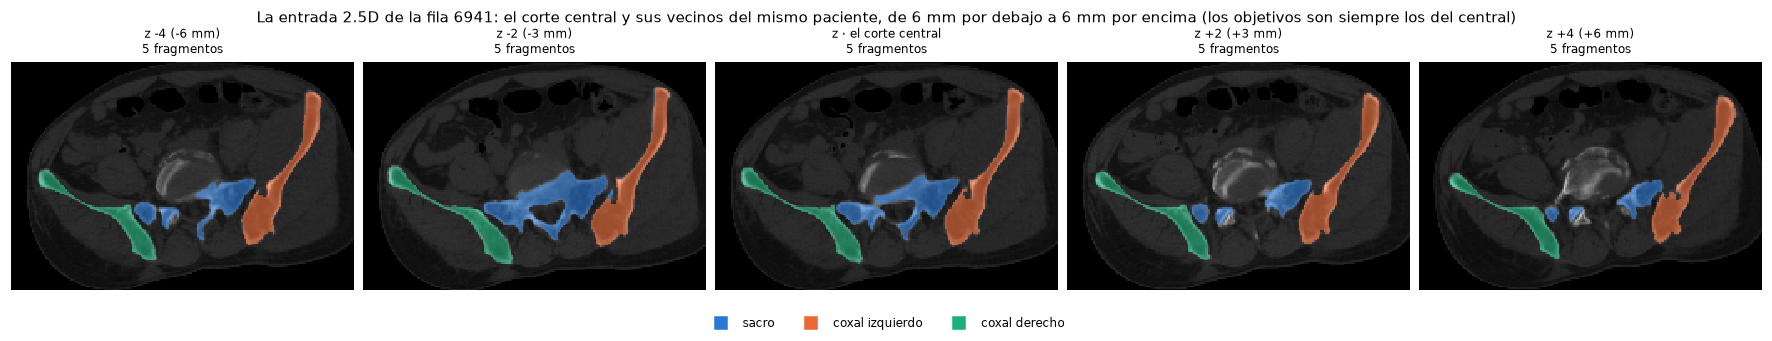

In [ ]:
filas_pila = filas_vecinas(fila, sorted(DESP))
ys, xs = np.nonzero(np.any([np.asarray(lab_cache[f]) > 0 for f in filas_pila], axis=0))
y0, y1, x0, x1 = max(ys.min() - 16, 0), min(ys.max() + 16, 255), max(xs.min() - 16, 0), min(xs.max() + 16, 255)
fig, axs = plt.subplots(1, len(DESP), figsize=(16, 3.0), layout="constrained")
for ax, d, f in zip(axs, sorted(DESP), filas_pila):
    lab_v = np.asarray(lab_cache[f])
    n_frag = len(np.unique(lab_v[lab_v > 0]))
    mostrar_corte(ax, np.asarray(hu_cache[f]), lab_v, titulo=("z · el corte central" if d == 0 else
                  f"z {d:+d} ({d * bc.ISO_MM:+.0f} mm)") + f"\n{n_frag} fragmento{'' if n_frag == 1 else 's'}")
    ax.set_xlim(x0, x1)
    ax.set_ylim(y1, y0)
leyenda_huesos(fig, loc="outside lower center", ncol=3, frameon=False)
fig.suptitle(f"La entrada 2.5D de la fila {fila}: el corte central y sus vecinos del mismo paciente, de 6 mm por debajo a 6 mm "
             f"por encima (los objetivos son siempre los del central)", fontsize=10)
plt.show()

La figura muestra que la forma y la cantidad de fragmentos pueden cambiar entre cortes del mismo paciente. Algunas partes del hueso aparecen en varios cortes, mientras que otras empiezan o dejan de verse al avanzar por la tomografía.

Esta información es útil porque el modelo no analiza el corte central de forma aislada, sino que también recibe información de los cortes cercanos. Aun así, los objetivos que debe predecir corresponden solamente al corte central, mientras que los vecinos funcionan como contexto adicional.

## 1.13. EDA

En esta sección analizamos los datos del caché para entender mejor cómo son las fracturas y qué características debemos tener en cuenta al construir el modelo. Cada análisis busca responder una pregunta y comprobar alguna decisión del diseño.

Para estudiar los fragmentos, utilizamos las etiquetas originales de cada paciente. Para los análisis por corte, trabajamos con el índice y las máscaras 2D del caché.

### Fragmentos por paciente

Primero revisamos cuántos fragmentos tiene cada paciente y cómo se distribuyen entre el sacro y los dos coxales. Esto nos permite conocer qué tan fragmentadas están las estructuras óseas y qué diferencias hay entre ellas.

#### Análisis 1. ¿Cuántas regiones anatómicas hay en un mismo corte?

Primero comprobamos cuántos cortes contienen una, dos o las tres regiones anatómicas. Esto es importante para elegir cómo plantear la clasificación: si aparecen varios huesos en un mismo corte, el modelo debe poder predecirlos simultáneamente y no elegir solamente uno.

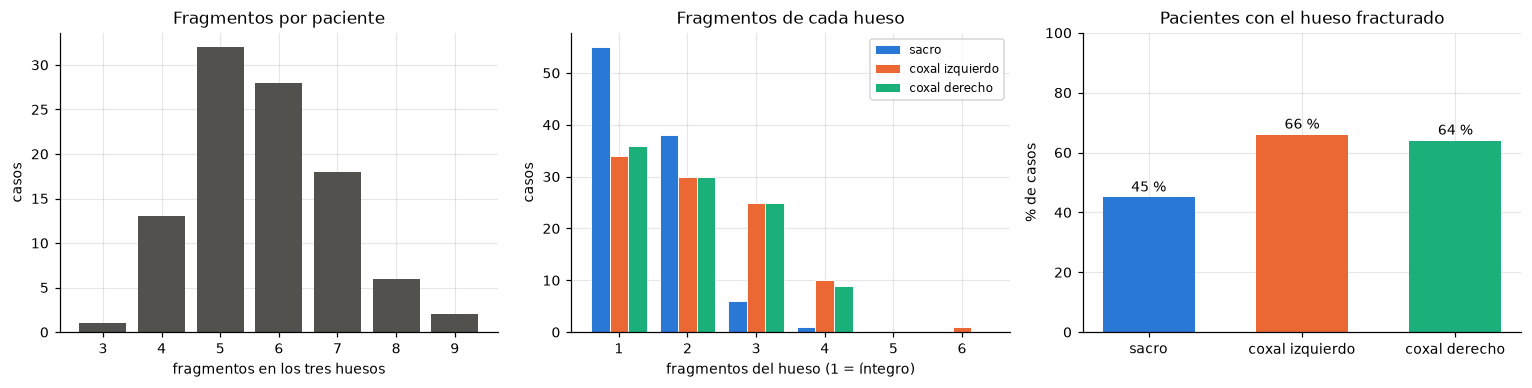

sacro           : íntegro en 55 casos · fracturado en el 45% · máximo 4 fragmentos
coxal izquierdo : íntegro en 34 casos · fracturado en el 66% · máximo 6 fragmentos
coxal derecho   : íntegro en 36 casos · fracturado en el 64% · máximo 4 fragmentos

Fragmentos por paciente: 3 – 9 (mediana 6) · 575 en total


In [ ]:
frag_caso = informe[list(FRAG.values())].set_axis(list(FRAG), axis=1)   
severidad = frag_caso.sum(axis=1)

fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
v, n = np.unique(severidad, return_counts=True)
axs[0].bar(v, n, color=NEUTRO, width=0.8)
axs[0].set(title="Fragmentos por paciente", xlabel="fragmentos en los tres huesos", ylabel="casos", xticks=v)

x = np.arange(1, frag_caso.to_numpy().max() + 1)
for i, k in enumerate(COLOR):
    axs[1].bar(x + (i - 1) * 0.27, frag_caso[k].value_counts().reindex(x, fill_value=0), 0.27,
               color=COLOR[k], label=HUESO[k], edgecolor="white", linewidth=0.6)
axs[1].set(title="Fragmentos de cada hueso", xlabel="fragmentos del hueso (1 = íntegro)", ylabel="casos", xticks=x)
axs[1].legend(fontsize=8)

pct = [100 * (frag_caso[k] > 1).mean() for k in COLOR]
axs[2].bar([HUESO[k] for k in COLOR], pct, color=list(COLOR.values()), width=0.6)
for i, p in enumerate(pct):
    axs[2].text(i, p + 2, f"{p:.0f} %", ha="center", fontsize=9)
axs[2].set(title="Pacientes con el hueso fracturado", ylabel="% de casos", ylim=(0, 100))
fig.tight_layout()
plt.show()

for k in COLOR:
    col = frag_caso[k]
    print(f"{HUESO[k]:<16}: íntegro en {int((col == 1).sum()):>2} casos · fracturado en el {(col > 1).mean():.0%} · "
          f"máximo {col.max()} fragmentos")
print(f"\nFragmentos por paciente: {severidad.min()} – {severidad.max()} (mediana {int(severidad.median())}) · "
      f"{severidad.sum()} en total")

En la gráfica se observa que el número de fragmentos varía entre los pacientes. La mayoría tiene entre 5 y 7 fragmentos sumando los tres huesos, y la mediana es de 6.

Al revisar cada hueso por separado, encontramos que el sacro está íntegro en 55 pacientes y fracturado en el 45 %. En el coxal izquierdo, 34 pacientes lo tienen íntegro y el 66 % presenta fractura. Para el coxal derecho, 36 pacientes lo tienen íntegro y el 64 % presenta fractura.

El coxal izquierdo alcanza hasta 6 fragmentos, mientras que el sacro y el coxal derecho llegan a un máximo de 4. En total, los 100 pacientes reúnen 575 fragmentos. Estos resultados muestran que los coxales presentan fracturas con mayor frecuencia que el sacro.

#### Por corte: lo que verá el modelo

El modelo predice los resultados del corte central, aunque también recibe cortes vecinos como contexto. Por eso, vamos a revisar cuántas regiones anatómicas aparecen en cada corte y qué implica esto para la clasificación.

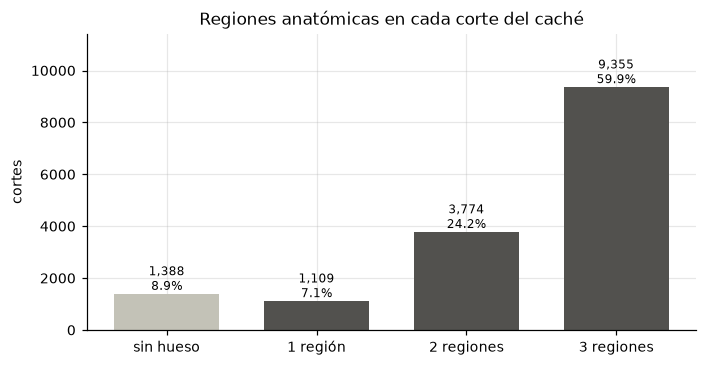

Cortes con más de una región: 84.0% · con las tres: 59.9%
Presencia de cada hueso en los cortes: sacro 60.1% · coxal izquierdo 87.7% · coxal derecho 87.1%
F1 macro de un predictor que responde siempre «las tres»: 0.872


In [ ]:
n = len(indice)
conteo = indice.n_regions.value_counts().reindex(range(4), fill_value=0)

fig, ax = plt.subplots(figsize=(6.5, 3.4))
barras = ax.bar(["sin hueso", "1 región", "2 regiones", "3 regiones"], conteo, color=[GRIS] + [NEUTRO] * 3, width=0.7)
for b, c in zip(barras, conteo):
    ax.text(b.get_x() + b.get_width() / 2, c + n * 0.01, f"{c:,}\n{c / n:.1%}", ha="center", fontsize=8)
ax.set(title="Regiones anatómicas en cada corte del caché", ylabel="cortes", ylim=(0, conteo.max() * 1.22))
fig.tight_layout()
plt.show()

prevalencia = np.array([((indice.bones_present.to_numpy() >> i) & 1).mean() for i in range(3)])
f1_constante = np.mean(2 * prevalencia / (1 + prevalencia))   
print(f"Cortes con más de una región: {(conteo[2] + conteo[3]) / n:.1%} · con las tres: {conteo[3] / n:.1%}")
print("Presencia de cada hueso en los cortes: " + " · ".join(f"{HUESO[k]} {p:.1%}" for k, p in zip(COLOR, prevalencia)))
print(f"F1 macro de un predictor que responde siempre «las tres»: {f1_constante:.3f}")

En la gráfica vemos que 9.355 cortes (59,9 %) contienen las tres regiones anatómicas y 3.774 (24,2 %) contienen dos. Además, 1.109 cortes (7,1 %) tienen una sola región y 1.388 (8,9 %) no contienen hueso.

En total, el 84 % de los cortes contiene dos o tres regiones. Esto significa que un mismo corte puede incluir varios huesos, por lo que el modelo debe poder identificarlos simultáneamente.

#### D1. Clasificación multietiqueta

Como en un mismo corte pueden aparecer varios huesos, utilizaremos tres sigmoides independientes, una para cada región anatómica, junto con entropía cruzada binaria. A diferencia de un softmax, este enfoque permite predecir que varios huesos están presentes al mismo tiempo.

Para evaluar la clasificación, utilizaremos F1 y AUC macro, además de una matriz de confusión para cada hueso frente al resto.

También debemos tener en cuenta que un predictor que siempre responde que los tres huesos están presentes obtiene un F1 macro de 0,872 en estos datos. Por eso, no basta con superar el F1 de 0,85 solicitado en el enunciado: debemos comparar el resultado con esta referencia y revisar también el AUC para evaluar mejor el desempeño del modelo.

#### Análisis 2. ¿Cuántos fragmentos hay en un corte?

Ahora revisamos cuántos fragmentos pueden aparecer en un mismo corte y cómo se distribuyen entre los tres huesos. Esto nos ayuda a definir cuántos fragmentos debe poder identificar el modelo durante la segmentación de instancias.

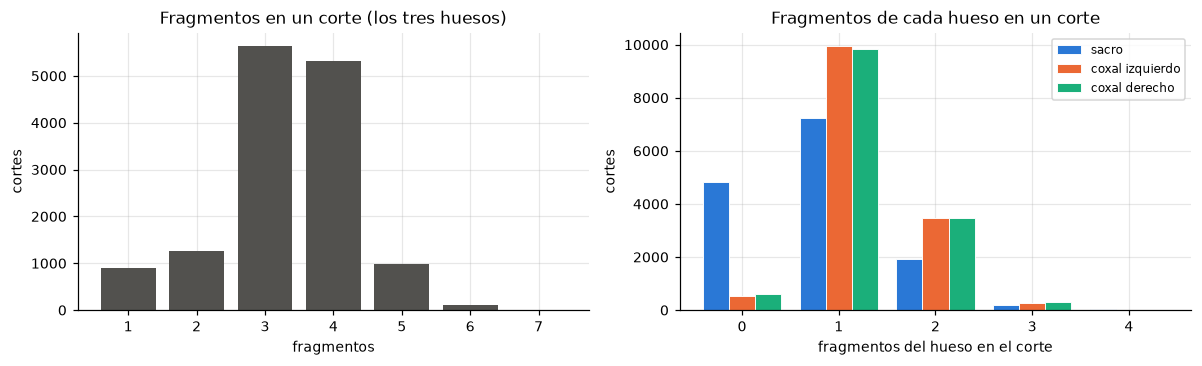

Fragmentos por corte con hueso: 1 – 7 (mediana 3)
  sacro           : hasta 4 fragmentos en un mismo corte
  coxal izquierdo : hasta 4 fragmentos en un mismo corte
  coxal derecho   : hasta 4 fragmentos en un mismo corte


In [29]:
ch = indice[indice.has_bone == 1]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
v, c = np.unique(ch.n_frag_total, return_counts=True)
axs[0].bar(v, c, color=NEUTRO, width=0.8)
axs[0].set(title="Fragmentos en un corte (los tres huesos)", xlabel="fragmentos", ylabel="cortes", xticks=v)
x = np.arange(0, max(ch[col].max() for col in FRAG.values()) + 1)
for i, k in enumerate(COLOR):
    axs[1].bar(x + (i - 1) * 0.27, ch[FRAG[k]].value_counts().reindex(x, fill_value=0), 0.27,
               color=COLOR[k], label=HUESO[k], edgecolor="white", linewidth=0.6)
axs[1].set(title="Fragmentos de cada hueso en un corte", xlabel="fragmentos del hueso en el corte", ylabel="cortes", xticks=x)
axs[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

print(f"Fragmentos por corte con hueso: {ch.n_frag_total.min()} – {ch.n_frag_total.max()} (mediana {int(ch.n_frag_total.median())})")
for k in COLOR:
    print(f"  {HUESO[k]:<16}: hasta {ch[FRAG[k]].max()} fragmentos en un mismo corte")

En los cortes que contienen hueso encontramos entre 1 y 7 fragmentos en total, con una mediana de 3. Sin embargo, al revisar cada hueso por separado, ninguno supera los 4 fragmentos en un mismo corte.

Esto significa que la cantidad de fragmentos varía según el corte y el hueso, por lo que debemos tener en cuenta el máximo observado para configurar el decodificador.

#### D2. Capacidad del decodificador

Con base en los resultados, configuraremos el decodificador para identificar hasta 4 fragmentos por hueso en cada corte, que es el máximo encontrado en los datos. Así ajustamos su capacidad a lo que realmente aparece en el conjunto, en lugar de reservar espacio para los 10 fragmentos que permite el formato de las etiquetas.

#### Análisis 3. ¿La ventana de hueso cubre el hueso?

Para comprobar si la ventana de hueso elegida es adecuada, revisamos las intensidades HU de los vóxeles que pertenecen a las máscaras óseas. Para esto, tomamos una muestra de 600 cortes y comparamos sus valores con el rango de la ventana del canal 0, que va de −200 a 1300 HU.

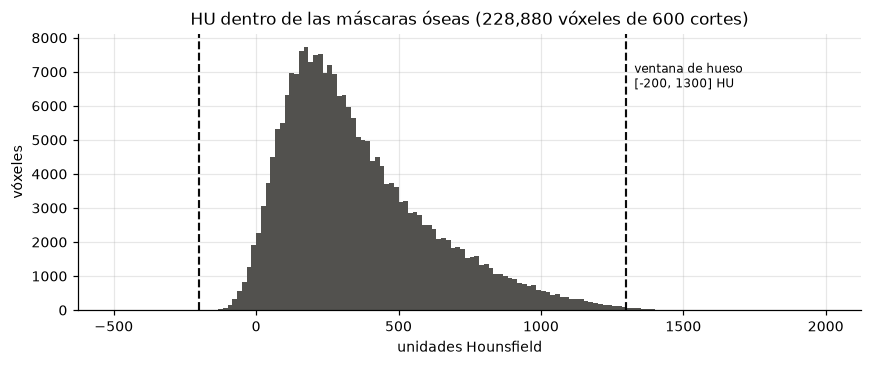

Percentiles: p1 -29 · p5 38 · p50 299 · p95 878 · p99 1,129 HU
La ventana [-200, 1300] cubre el 99.83% de los vóxeles óseos


Rango completo del caché: -5,526 … 24,496 HU


In [30]:
rng = np.random.default_rng(42)
filas_muestra = np.sort(rng.choice(ch.row.to_numpy(), size=600, replace=False))
valores = []
for f in filas_muestra:
    v = np.asarray(hu_cache[f])[np.asarray(lab_cache[f]) > 0]
    valores.append(rng.choice(v, size=min(400, v.size), replace=False))
hu_hueso = np.concatenate(valores)

lo, hi = VENTANAS[0]
cobertura = float(((hu_hueso >= lo) & (hu_hueso <= hi)).mean())
p = np.percentile(hu_hueso, [1, 5, 50, 95, 99])

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(hu_hueso, bins=150, range=(-500, 2000), color=NEUTRO)
for lim in (lo, hi):
    ax.axvline(lim, color=TINTA, ls="--", lw=1.4)
ax.text(hi, ax.get_ylim()[1] * 0.9, f"  ventana de hueso\n  [{lo}, {hi}] HU", fontsize=8, va="top")
ax.set(title=f"HU dentro de las máscaras óseas ({len(hu_hueso):,} vóxeles de {len(filas_muestra)} cortes)",
       xlabel="unidades Hounsfield", ylabel="vóxeles")
fig.tight_layout()
plt.show()

print("Percentiles: " + " · ".join(f"p{q} {v:,.0f}" for q, v in zip((1, 5, 50, 95, 99), p)) + " HU")
print(f"La ventana [{lo}, {hi}] cubre el {cobertura:.2%} de los vóxeles óseos")
print(f"Rango completo del caché: {int(hu_cache.min()):,} … {int(hu_cache.max()):,} HU")

La ventana de hueso cubre el 99,83 % de los vóxeles óseos de la muestra. Además, la mediana es de 299 HU y el 95 % de los valores está por debajo de 878 HU. Esto indica que el rango seleccionado conserva la mayor parte de la información de las estructuras óseas, por lo que lo mantendremos para el canal 0.

También encontramos valores extremos en el caché, desde −5526 hasta 24.496 HU. Estos valores pueden estar relacionados con la presencia de material metálico y los artefactos que produce en la tomografía. Los tendremos en cuenta al documentar las limitaciones de los datos y el comportamiento del preprocesamiento.

#### D3. Ventana de hueso confirmada

Los resultados muestran que la ventana de [-200, 1300] HU cubre el 99,83 % de los vóxeles óseos analizados, por lo que mantendremos este rango para el canal 0.

Los valores que quedan fuera del rango se recortan durante la normalización. Esto también afecta a las intensidades extremas que pueden aparecer por la presencia de metal en algunas tomografías.

#### Análisis 4. ¿Tiene resolución suficiente la grilla de detección?

La cabeza de detección utiliza una grilla de 16 × 16 celdas, donde cada celda corresponde a 16 × 16 píxeles de la imagen. Para comprobar si esta resolución es adecuada, medimos el lado mayor de las cajas que delimitan cada región ósea en todos los cortes con hueso.

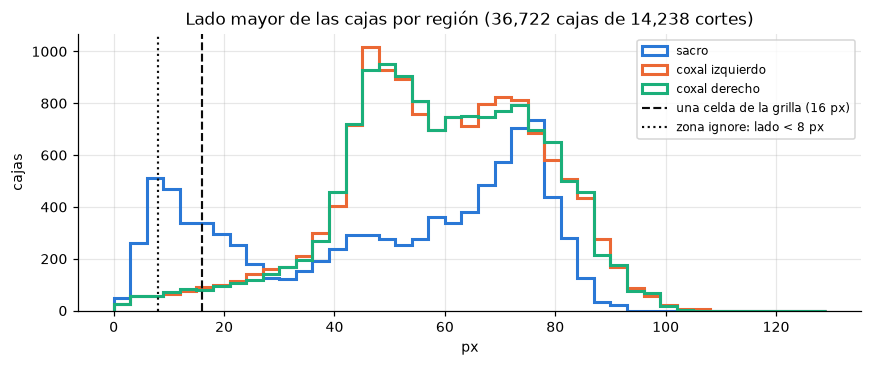

sacro           :   1 –  92 px · mediana 54 px = 3.4 celdas
coxal izquierdo :   1 – 106 px · mediana 59 px = 3.7 celdas
coxal derecho   :   1 – 102 px · mediana 59 px = 3.7 celdas

Cajas menores que una celda: 6.5% · menores de 8 px: 2.3%  (3 s)


In [31]:
t0 = time.perf_counter()
cajas_gt = pd.DataFrame([{"hueso": k, "ancho": x1 - x0, "alto": y1 - y0}
                         for f in ch.row.to_numpy()
                         for k, (x0, y0, x1, y1) in cajas_por_region(np.asarray(lab_cache[f])).items()])
cajas_gt["lado"] = cajas_gt[["ancho", "alto"]].max(axis=1)
CELDA = bc.CROP_PX // 16

fig, ax = plt.subplots(figsize=(8, 3.4))
for k in COLOR:
    ax.hist(cajas_gt.lado[cajas_gt.hueso == k], bins=np.arange(0, 130, 3), histtype="step", lw=2,
            color=COLOR[k], label=HUESO[k])
ax.axvline(CELDA, color=TINTA, ls="--", lw=1.4, label=f"una celda de la grilla ({CELDA} px)")
ax.axvline(8, color=TINTA, ls=":", lw=1.4, label="zona ignore: lado < 8 px")
ax.set(title=f"Lado mayor de las cajas por región ({len(cajas_gt):,} cajas de {len(ch):,} cortes)", xlabel="px", ylabel="cajas")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

for k in COLOR:
    s = cajas_gt.lado[cajas_gt.hueso == k]
    print(f"{HUESO[k]:<16}: {s.min():>3} – {s.max():>3} px · mediana {int(s.median())} px = {s.median() / CELDA:.1f} celdas")
print(f"\nCajas menores que una celda: {(cajas_gt.lado < CELDA).mean():.1%} · menores de 8 px: {(cajas_gt.lado < 8).mean():.1%}"
      f"  ({time.perf_counter() - t0:.0f} s)")

La mediana del lado mayor de las cajas es de 54 píxeles para el sacro y de 59 para cada coxal. Esto equivale aproximadamente a entre 3 y 4 celdas de la grilla, por lo que la resolución parece suficiente para detectar las regiones en la mayoría de los casos.

Sin embargo, el 6,5 % de las cajas mide menos de 16 píxeles y el 2,3 % tiene un lado menor de 8 píxeles. Estas cajas tan pequeñas suelen aparecer cuando el hueso apenas se ve en los cortes extremos, lo que puede dificultar su detección.

#### D4. Resolución de la grilla

Mantendremos la grilla de 16 × 16 celdas, ya que la mayoría de las cajas ocupa varias celdas. En lugar de aumentar la resolución para detectar fragmentos muy pequeños, trataremos las cajas con un lado menor de 8 píxeles como regiones que se deben ignorar durante el entrenamiento, según la configuración del modelo.

#### En 3D: la geometría de los fragmentos

Hasta ahora hemos analizado los datos por corte, pero los fragmentos son estructuras tridimensionales. Por eso, para medir su volumen y la distancia entre ellos, necesitamos reconstruir el volumen completo de cada paciente a partir de sus cortes.

Para cada fragmento calculamos tres características:

- **Volumen:** cantidad de vóxeles que ocupa, convertida a mm³.
- **Piezas conexas:** número de partes separadas en las que aparece el fragmento.
- **Separación:** distancia mínima entre el fragmento y el fragmento principal de su hueso, definido como el de mayor volumen. La distancia se calcula en 3D con `scipy.ndimage.distance_transform_edt` y el espaciado físico de 1,5 mm.

Este análisis se realiza primero con las máscaras originales para conocer las características de los fragmentos y comprobar que el cálculo de distancias funcione correctamente. También servirá como referencia para definir el umbral de fragmentos pequeños que se utilizará en el postprocesamiento.

Más adelante, en la sección 4.6, aplicaremos la misma función a las máscaras predichas por el modelo para calcular la separación entre fragmentos.

In [ ]:
VOX_MM3 = bc.ISO_MM ** 3


def separacion_mm(lab3d, v, principal, cajas, espaciado=(bc.ISO_MM,) * 3, margen=2):
    caja = tuple(slice(max(min(a.start, b.start) - margen, 0), max(a.stop, b.stop) + margen)
                 for a, b in zip(cajas[v - 1], cajas[principal - 1]))
    trozo = lab3d[caja]
    distancia = ndimage.distance_transform_edt(trozo != principal, sampling=espaciado)
    return float(distancia[trozo == v].min())


def fragmentos_del_caso(lab3d: np.ndarray, caso: str) -> list[dict]:
    vox = np.bincount(lab3d.ravel(), minlength=31)
    cajas = ndimage.find_objects(lab3d)
    filas = []
    for k in (1, 2, 3):
        presentes = [v for v in range(10 * k - 9, 10 * k + 1) if vox[v]]
        if not presentes:
            continue
        principal = max(presentes, key=lambda v: vox[v])
        for v in presentes:
            piezas, n = ndimage.label(lab3d[cajas[v - 1]] == v, structure=np.ones((3, 3, 3)))
            tam = np.sort(np.bincount(piezas.ravel())[1:])[::-1] * VOX_MM3
            filas.append({"case_id": caso, "hueso": k, "etiqueta": v, "principal": v == principal,
                          "volumen_mm3": vox[v] * VOX_MM3, "piezas": n,
                          "pieza_mayor": tam[0] / tam.sum(), "segunda_pieza_mm3": tam[1] if n > 1 else 0.0,
                          "separacion_mm": 0.0 if v == principal else separacion_mm(lab3d, v, principal, cajas)})
    return filas


prueba = np.zeros((10, 10, 30), np.uint8)
prueba[2:8, 2:8, 0:10] = 11
prueba[3:6, 3:6, 10:13] = 12
prueba[3:6, 3:6, 16:19] = 13
cajas_prueba = ndimage.find_objects(prueba)
assert separacion_mm(prueba, 12, 11, cajas_prueba) == 1.5 and separacion_mm(prueba, 13, 11, cajas_prueba) == 10.5
print("separacion_mm() en el caso de solución conocida: 1.5 y 10.5 mm ✓\n")

t0 = time.perf_counter()
filas = []
for c, g in indice.groupby("case_id"):
    assert (np.diff(g.row) == 1).all() and (np.diff(g.z) == 1).all()
    filas += fragmentos_del_caso(np.asarray(lab_cache[g.row.iat[0]:g.row.iat[-1] + 1]), c)
frag = pd.DataFrame(filas)

assert (frag.groupby(["case_id", "hueso"]).size().unstack(fill_value=0).to_numpy() == frag_caso.to_numpy()).all()
print(f"{len(frag)} fragmentos de {frag.case_id.nunique()} pacientes en {time.perf_counter() - t0:.0f} s: "
      f"{int(frag.principal.sum())} principales y {int((~frag.principal).sum())} conminutos")

separacion_mm() en el caso de solución conocida: 1.5 y 10.5 mm ✓



575 fragmentos de 100 pacientes en 26 s: 300 principales y 275 conminutos


#### Análisis 5. ¿Cuánto se separan los fragmentos?

Después de calcular la distancia de cada fragmento al fragmento principal de su hueso, revisamos cómo se distribuyen esas distancias. Esto nos permite saber si los fragmentos están cerca del principal o si presentan una separación mayor.

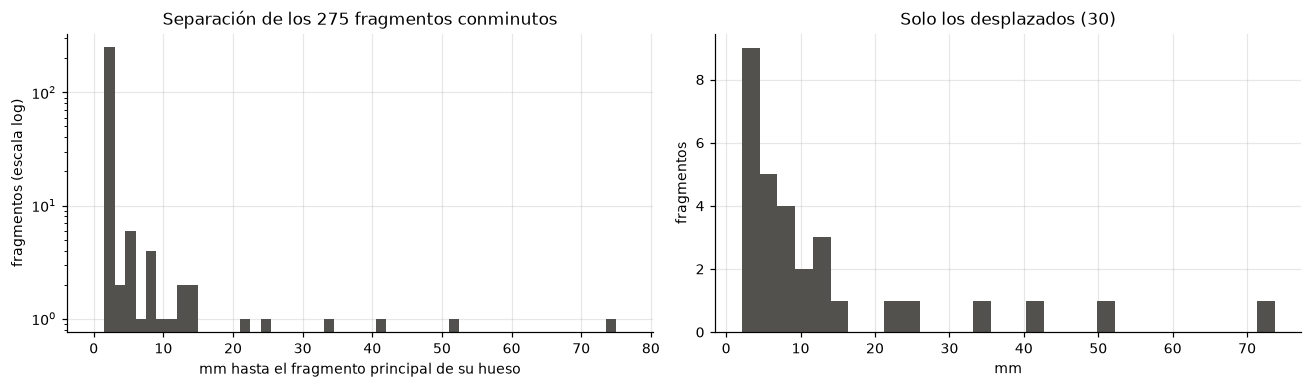

Percentiles: p5 1.50 · p25 1.50 · p50 1.50 · p75 1.50 · p95 7.65 · máximo 73.7 mm
En contacto con su principal (1.5 mm = un vóxel): 89.1% (245 de 275)


In [ ]:
conm = frag[~frag.principal]
d = conm.separacion_mm
en_contacto = d <= bc.ISO_MM + 1e-6             
q = np.percentile(d, [5, 25, 50, 75, 95])

fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
axs[0].hist(d, bins=np.arange(0, d.max() + 3, 1.5), color=NEUTRO)
axs[0].set_yscale("log")
axs[0].set(title=f"Separación de los {len(d)} fragmentos conminutos", xlabel="mm hasta el fragmento principal de su hueso",
           ylabel="fragmentos (escala log)")
axs[1].hist(d[~en_contacto], bins=30, color=NEUTRO)
axs[1].set(title=f"Solo los desplazados ({int((~en_contacto).sum())})", xlabel="mm", ylabel="fragmentos")
fig.tight_layout()
plt.show()

print("Percentiles: " + " · ".join(f"p{k} {v:.2f}" for k, v in zip((5, 25, 50, 75, 95), q)) + f" · máximo {d.max():.1f} mm")
print(f"En contacto con su principal (1.5 mm = un vóxel): {en_contacto.mean():.1%} ({int(en_contacto.sum())} de {len(d)})")

Los resultados muestran que 245 de los 275 fragmentos conminutos (89,1 %) están a una distancia de 1,5 mm del fragmento principal, equivalente a un vóxel. Esto indica que la mayoría están en contacto o muy cerca de la estructura principal. Sin embargo, algunos presentan separaciones mayores, y la distancia máxima registrada es de 73,7 mm.

Este resultado es importante para la arquitectura del modelo. Si intentáramos identificar cada fragmento únicamente buscando componentes conexas en la máscara de segmentación, los fragmentos que están en contacto podrían quedar agrupados como una sola pieza. Por eso, necesitaremos un método que permita distinguir los fragmentos incluso cuando están unidos en la máscara.

#### D5. Separación de instancias

Como muchos fragmentos están en contacto con el fragmento principal, no podemos distinguirlos únicamente mediante componentes conexas. Por eso, el modelo también utilizará un mapa de calor para localizar el centro de cada fragmento y un campo de desplazamientos que indique hacia dónde debe dirigirse cada píxel para llegar a su centro.

De esta manera, dos fragmentos que estén en contacto podrán identificarse como instancias diferentes. Sin embargo, la resolución del volumen limita la precisión de las distancias, por lo que esta limitación debe tenerse en cuenta al interpretar los resultados.

#### Análisis 6. ¿Qué tamaño tienen los fragmentos pequeños?

El postprocesamiento necesita un umbral para descartar posibles fragmentos pequeños generados por ruido. Para elegirlo, analizamos el volumen de los fragmentos conminutos reales y lo comparamos con el de los fragmentos principales.

La idea es establecer un umbral que permita eliminar algunas detecciones pequeñas sin descartar demasiados fragmentos reales.

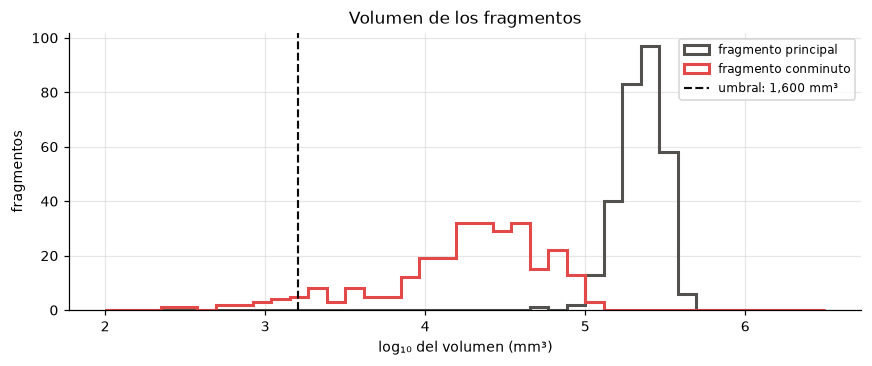

Principales: mediana 229,539 mm³
Conminutos : mínimo 287 · p1 603 · p5 1,554 · mediana 22,029 mm³

Conminutos reales por debajo de 1,600 mm³: 15 de 275 (5.5%), de ellos 8 desplazados (de 30 desplazados en total)
Volumen mediano: desplazados 6,286 mm³ · en contacto 24,374 mm³


In [ ]:
pv = np.percentile(conm.volumen_mm3, [1, 5, 50])
umbral_mm3 = max(round(pv[1] / 100) * 100, 100)      
desplazados = ~en_contacto
bajo = conm.volumen_mm3 < umbral_mm3

fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.linspace(2, 6.5, 40)
ax.hist(np.log10(frag.volumen_mm3[frag.principal]), bins=bins, histtype="step", lw=2, color=NEUTRO, label="fragmento principal")
ax.hist(np.log10(conm.volumen_mm3), bins=bins, histtype="step", lw=2, color="#e34948", label="fragmento conminuto")
ax.axvline(np.log10(umbral_mm3), color=TINTA, ls="--", lw=1.4, label=f"umbral: {umbral_mm3:,.0f} mm³")
ax.set(title="Volumen de los fragmentos", xlabel="log₁₀ del volumen (mm³)", ylabel="fragmentos")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

print(f"Principales: mediana {frag.volumen_mm3[frag.principal].median():,.0f} mm³")
print(f"Conminutos : mínimo {conm.volumen_mm3.min():,.0f} · p1 {pv[0]:,.0f} · p5 {pv[1]:,.0f} · mediana {pv[2]:,.0f} mm³")
print(f"\nConminutos reales por debajo de {umbral_mm3:,.0f} mm³: {int(bajo.sum())} de {len(conm)} ({bajo.mean():.1%}), "
      f"de ellos {int((bajo & desplazados).sum())} desplazados (de {int(desplazados.sum())} desplazados en total)")
print(f"Volumen mediano: desplazados {conm.volumen_mm3[desplazados].median():,.0f} mm³ · "
      f"en contacto {conm.volumen_mm3[~desplazados].median():,.0f} mm³")

Los fragmentos principales tienen un volumen mediano de 229.539 mm³, mientras que los fragmentos conminutos tienen una mediana de 22.029 mm³. Como se observa en la gráfica, los fragmentos conminutos suelen tener un volumen menor, aunque existe bastante variación entre ellos.

El percentil 5 del volumen de los fragmentos conminutos es de 1.554 mm³. A partir de este resultado, se establece un umbral de 1.600 mm³ para el postprocesamiento.

Con este umbral, 15 de los 275 fragmentos reales (5,5 %) quedan por debajo del límite. De ellos, 8 presentan una separación mayor de 1,5 mm respecto al fragmento principal. Por tanto, el umbral puede ayudar a eliminar detecciones pequeñas, pero también podría eliminar fragmentos reales.

Por esta razón, tendremos que comprobar su efecto durante la evaluación del modelo y ajustar el postprocesamiento según los resultados obtenidos.

#### D6. Umbral de fragmento espurio

Establecemos un umbral de 1.600 mm³ para descartar fragmentos pequeños que puedan aparecer como ruido en las predicciones. Este valor se basa en el percentil 5 de los fragmentos conminutos reales, que es de 1.554 mm³, redondeado a la centena.

Sin embargo, este umbral también podría eliminar fragmentos reales. En los datos analizados, 15 fragmentos están por debajo del límite, incluidos 8 de los 30 fragmentos desplazados. Por eso, durante la evaluación tendremos que revisar cómo afecta esta decisión a la medición de las distancias.

#### Análisis 7. ¿Es cada fragmento una sola pieza?

Antes de reconstruir los fragmentos en 3D a partir de las predicciones de cada corte, debemos comprobar si cada etiqueta representa una única pieza conectada o si algunos fragmentos aparecen divididos en varias partes separadas.

Esto nos permitirá saber si podemos asumir que cada fragmento es una estructura conexa durante la reconstrucción tridimensional.

In [35]:
partidos = frag[frag.piezas > 1]
motas = partidos[partidos.segunda_pieza_mm3 < umbral_mm3]
reales = partidos[partidos.segunda_pieza_mm3 >= umbral_mm3]

print(f"Fragmentos anotados en más de una pieza conexa: {len(partidos)} de {len(frag)} ({len(partidos) / len(frag):.1%})")
print(f"  hasta {partidos.piezas.max()} piezas · la pieza mayor concentra una mediana del {partidos.pieza_mayor.median():.2%} "
      f"del volumen (mínimo {partidos.pieza_mayor.min():.1%})")
print(f"  la segunda pieza mide una mediana de {partidos.segunda_pieza_mm3.median():.0f} mm³ "
      f"({partidos.segunda_pieza_mm3.median() / VOX_MM3:.0f} vóxeles); máximo {partidos.segunda_pieza_mm3.max():,.0f} mm³")
print(f"\n  → motas (segunda pieza < {umbral_mm3:,.0f} mm³): {len(motas)}")
print(f"  → divisiones reales                 : {len(reales)}  " +
      ", ".join(f"caso {r.case_id}, etiqueta {r.etiqueta}" for r in reales.itertuples()))

Fragmentos anotados en más de una pieza conexa: 100 de 575 (17.4%)
  hasta 5 piezas · la pieza mayor concentra una mediana del 99.96% del volumen (mínimo 69.4%)
  la segunda pieza mide una mediana de 34 mm³ (10 vóxeles); máximo 3,928 mm³

  → motas (segunda pieza < 1,600 mm³): 99
  → divisiones reales                 : 1  caso 039, etiqueta 12


Los resultados muestran que 100 de los 575 fragmentos (17,4 %) aparecen en más de una pieza conexa. Sin embargo, en 99 de esos casos, las piezas adicionales son muy pequeñas: la pieza mayor concentra una mediana del 99,96 % del volumen total.

Solo encontramos un caso con una segunda pieza de tamaño superior al umbral de 1.600 mm³: el caso 039, etiqueta 12. Esto indica que la mayoría de las divisiones corresponden a pequeñas partes aisladas, mientras que existe un caso en el que una misma etiqueta representa dos piezas separadas.

#### D7. Reconstrucción 3D y conectividad

Durante la reconstrucción tridimensional, utilizaremos el umbral de 1.600 mm³ para filtrar las piezas pequeñas que puedan aparecer separadas de su fragmento principal.

El caso 039, en el que una etiqueta corresponde a dos piezas de mayor tamaño, se documentará como una limitación conocida. Esto muestra que no siempre es posible recuperar la estructura original de un fragmento únicamente a partir de su conectividad.

#### Análisis 8. ¿Cuánto cambia la anatomía entre cortes vecinos?

Este análisis busca comprobar qué información aportan los cortes vecinos a la entrada 2.5D. Si dos cortes son demasiado parecidos, el segundo puede aportar poca información adicional; si están muy separados, la anatomía puede cambiar considerablemente.

Para estudiarlo, seleccionaremos 2.000 cortes con hueso y los compararemos con cortes del mismo paciente situados a distintas distancias: 1, 2, 3, 4, 6 y 8 cortes, equivalentes a 1,5, 3, 4,5, 6, 9 y 12 mm.

Mediremos tres aspectos: los cambios en los huesos presentes, los cambios en la cantidad de fragmentos y la similitud entre las máscaras de cada hueso mediante el coeficiente Dice.

In [ ]:
rng = np.random.default_rng(0)
base = rng.choice(ch.row.to_numpy(), 2000, replace=False)
cambio = []
for d in (1, 2, 3, 4, 6, 8):
    otra = np.clip(base + d, _ini[base], _fin[base])
    presentes = (indice.bones_present.to_numpy()[base] != indice.bones_present.to_numpy()[otra]).mean()
    n_frag = (indice[list(FRAG.values())].to_numpy()[base] != indice[list(FRAG.values())].to_numpy()[otra]).any(1).mean()
    dices = []
    for a, b in zip(base[:600], otra[:600]):
        ha, hb = a_hueso(np.asarray(lab_cache[a])), a_hueso(np.asarray(lab_cache[b]))
        dices += [2 * ((ha == k) & (hb == k)).sum() / ((ha == k).sum() + (hb == k).sum()) for k in (1, 2, 3) if (ha == k).any()]
    cambio.append({"d (cortes)": d, "mm": d * bc.ISO_MM, "cambia qué huesos hay": presentes,
                   "cambia el n.º de fragmentos": n_frag, "Dice de cada hueso entre z y z + d": float(np.mean(dices))})
cambio = pd.DataFrame(cambio).set_index("d (cortes)")
cambio.round(3)

,mm,cambia qué huesos hay,cambia el n.º de fragmentos,Dice de cada hueso entre z y z + d
d (cortes),,,,
1,1.5,0.038,0.074,0.904
2,3.0,0.069,0.135,0.829
3,4.5,0.098,0.187,0.763
4,6.0,0.126,0.232,0.703
6,9.0,0.180,0.328,0.601
8,12.0,0.226,0.408,0.513


Los resultados muestran que los cortes muy cercanos se parecen bastante entre sí. A una distancia de 1,5 mm, el Dice promedio es de 0,904 y solo en el 3,8 % de los casos cambia qué huesos están presentes.

Al aumentar la distancia, las diferencias son mayores. A 6 mm, el Dice baja a 0,703, en el 12,6 % de los casos cambia la presencia de algún hueso y en el 23,2 % cambia la cantidad de fragmentos. A 12 mm, el Dice llega a 0,513.

Esto indica que los cortes vecinos pueden aportar información sobre cómo cambia la anatomía, pero cuanto más lejos están del corte central, menos se parecen a él.

#### D8. Comparación de las pilas 2.5D

A partir de estos resultados, evaluaremos tres configuraciones: tres cortes separados por 1,5 mm, tres cortes separados por 3 mm y cinco cortes que abarcan desde 6 mm por debajo hasta 6 mm por encima del central.

La idea es comparar cuánto contexto aporta cada opción. Sin embargo, la decisión final no se toma únicamente con este análisis, sino que se compararán las tres configuraciones durante el entrenamiento y se elegirá la que obtenga mejores resultados en validación, como se explica en la sección 3.3.

## 1.14. La partición de los datos

Antes de entrenar el modelo, debemos separar los pacientes en conjuntos de entrenamiento, validación y prueba. Esta división es importante porque queremos comprobar si el modelo funciona con pacientes que no ha visto durante el entrenamiento.

La partición debe hacerse por paciente y no por corte. Si mezcláramos cortes del mismo paciente entre entrenamiento y prueba, el modelo podría encontrarse con imágenes casi iguales en ambos conjuntos y obtener métricas demasiado optimistas.

Esto es aún más importante con la entrada 2.5D, porque cada ejemplo incluye cortes vecinos del mismo paciente. Por eso, todos los cortes de un paciente deben permanecer en el mismo conjunto.

También debemos tener en cuenta que algunos pacientes tienen muchos más fragmentos que otros. Para evitar que los conjuntos queden con una distribución muy diferente de casos sencillos y complejos, utilizaremos una partición estratificada según el número total de fragmentos de cada paciente.

In [ ]:
SEMILLA, FRACCIONES, PARTICIONES = 42, (0.70, 0.15, 0.15), ("train", "val", "test")


def estratos(severidad: pd.Series, n: int = 3) -> pd.Series:
    g = pd.Series(pd.qcut(severidad, n, labels=False, duplicates="drop"), index=severidad.index).fillna(0).astype(int)
    for k, m in sorted(g.value_counts().items()):
        if m < 3 and k > 0:
            g = g.replace(k, k - 1)
    return g


def particionar(severidad: pd.Series) -> dict[str, list[str]]:
    rng = np.random.default_rng(SEMILLA)
    grupos = estratos(severidad)
    out = {p: [] for p in PARTICIONES}
    for k in sorted(grupos.unique()):
        ids = np.array(sorted(severidad.index[grupos == k]))
        rng.shuffle(ids)
        c1 = int(round(FRACCIONES[0] * len(ids)))
        c2 = c1 + int(round(FRACCIONES[1] * len(ids)))
        for p, trozo in zip(PARTICIONES, (ids[:c1], ids[c1:c2], ids[c2:])):
            out[p] += trozo.tolist()
    return {p: sorted(v) for p, v in out.items()}


splits = particionar(severidad)
assert sorted(sum(splits.values(), [])) == casos

ruta = RAIZ / "splits.json"
if ruta.exists():
    assert json.loads(ruta.read_text(encoding="utf-8"))["splits"] == splits, "¡la partición ha cambiado!"
ruta.write_text(json.dumps({
    "seed": SEMILLA, "fractions": dict(zip(PARTICIONES, FRACCIONES)), "level": "case_id",
    "n_cases": {p: len(v) for p, v in splits.items()}, "stratified_by": "n_fragmentos_por_caso",
    "note": "Particion POR PACIENTE (case_id). Ver pengwin_desarrollo.ipynb, seccion 1.14.", "splits": splits,
}, indent=2, ensure_ascii=False), encoding="utf-8")


def filas_de(particion: str) -> np.ndarray:
    return indice.row[indice.case_id.isin(splits[particion])].to_numpy()


pd.DataFrame({p: {
    "pacientes": len(splits[p]),
    "cortes": f"{len(filas_de(p)):,} ({len(filas_de(p)) / len(indice):.1%})",
    "fragmentos por paciente": f"{severidad[splits[p]].mean():.2f}",
    **{f"{HUESO[k]} fracturado": f"{(frag_caso.loc[splits[p], k] > 1).mean():.0%}" for k in COLOR},
} for p in PARTICIONES}).T

,pacientes,cortes,fragmentos por paciente,sacro fracturado,coxal izquierdo fracturado,coxal derecho fracturado
train,70,"10,969 (70.2%)",5.76,50%,66%,64%
val,15,"2,364 (15.1%)",5.67,20%,80%,60%
test,15,"2,293 (14.7%)",5.80,47%,53%,67%


La partición quedó distribuida en 70 pacientes para entrenamiento, 15 para validación y 15 para prueba. En cuanto a los cortes, cada grupo representa aproximadamente el 70 %, el 15 % y el 15 % del total.

La severidad media también es similar: 5,76 fragmentos por paciente en entrenamiento, 5,67 en validación y 5,80 en prueba. Esto indica que la distribución según el número total de fragmentos quedó bastante equilibrada.

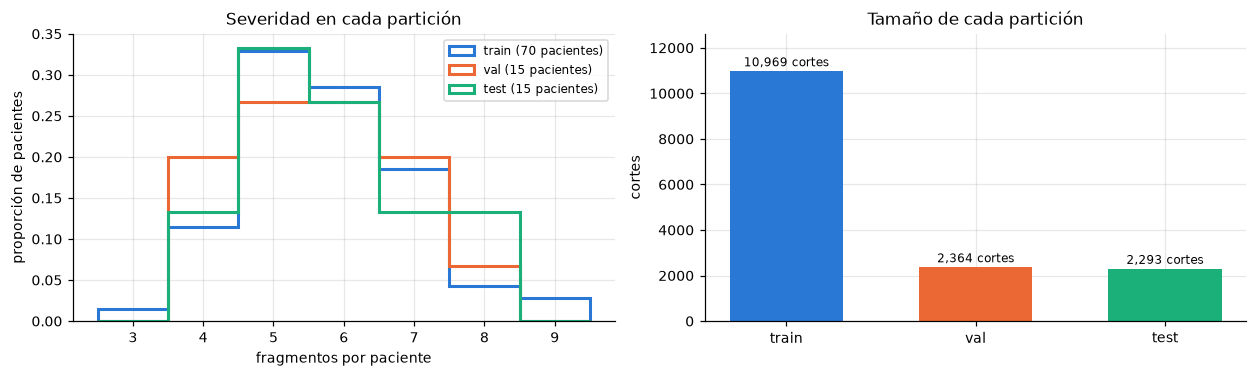

Pasos por época de entrenamiento: lote 8 → 1371 · lote 16 → 685 · lote 32 → 342


In [38]:
fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.5))
bins = np.arange(severidad.min() - 0.5, severidad.max() + 1.5)
for p, color in zip(PARTICIONES, COLOR.values()):
    axs[0].hist(severidad[splits[p]], bins=bins, density=True, histtype="step", lw=2, color=color,
                label=f"{p} ({len(splits[p])} pacientes)")
axs[0].set(title="Severidad en cada partición", xlabel="fragmentos por paciente", ylabel="proporción de pacientes")
axs[0].legend(fontsize=8)
cortes = [len(filas_de(p)) for p in PARTICIONES]
axs[1].bar(PARTICIONES, cortes, color=list(COLOR.values()), width=0.6)
for i, c in enumerate(cortes):
    axs[1].text(i, c + max(cortes) * 0.02, f"{c:,} cortes", ha="center", fontsize=8)
axs[1].set(title="Tamaño de cada partición", ylabel="cortes", ylim=(0, max(cortes) * 1.15))
fig.tight_layout()
plt.show()

print("Pasos por época de entrenamiento: " + " · ".join(f"lote {b} → {len(filas_de('train')) // b}" for b in (8, 16, 32)))

En la gráfica se observa que la distribución de fragmentos por paciente es parecida entre los tres grupos. Sin embargo, las proporciones de pacientes con cada hueso fracturado varían más. Por ejemplo, en validación el 20 % tiene el sacro fracturado, frente al 50 % en entrenamiento.

Esto se debe a que la estratificación se realizó según el número total de fragmentos y no por separado para cada hueso. Además, como validación y prueba tienen solo 15 pacientes, cada caso representa aproximadamente el 6,7 % del grupo.

Por eso, al comparar las métricas por hueso, tendremos que considerar estas diferencias y evitar sacar conclusiones únicamente a partir de porcentajes pequeños.

#### D9. Partición por paciente y severidad

La partición final utiliza 70 pacientes para entrenamiento, 15 para validación y 15 para prueba, con la semilla 42 y una distribución basada en el número total de fragmentos por paciente. Los resultados se guardan en `splits.json` para mantener la misma división durante todo el proyecto.

Si al volver a ejecutar el código la partición es diferente, la comprobación detiene la ejecución en lugar de sobrescribir el archivo. Así evitamos cambiar los grupos sin darnos cuenta.

La partición de prueba se reservará para la evaluación final y no se utilizará para tomar decisiones durante el entrenamiento. También es importante guardar una copia de `splits.json`, porque necesitamos conservar la misma división para que los resultados sean comparables.

### Cierre del capítulo 1

En este capítulo revisamos los 100 pacientes y preparamos las tomografías para poder utilizarlas en el modelo. Después de corregir la orientación, ajustar el espaciado y recortar las imágenes, construimos un caché de 15.626 cortes de 256 × 256 píxeles. También comprobamos que el recorte no perdiera vóxeles de hueso y que las máscaras conservaran sus etiquetas.

Con el análisis exploratorio definimos varios aspectos del modelo: utilizar tres canales con diferentes ventanas HU, incluir cortes vecinos como entrada 2.5D, permitir que se detecten varios huesos en un mismo corte y separar los fragmentos mediante una estrategia que no dependa únicamente de que estén conectados.

También dejamos preparada la partición de los pacientes en entrenamiento, validación y prueba, manteniendo a cada paciente en un solo grupo.

Con esto tenemos los datos organizados y una primera configuración del modelo. En los siguientes capítulos probaremos estas decisiones durante el entrenamiento y revisaremos los resultados para determinar cuáles funcionan mejor.

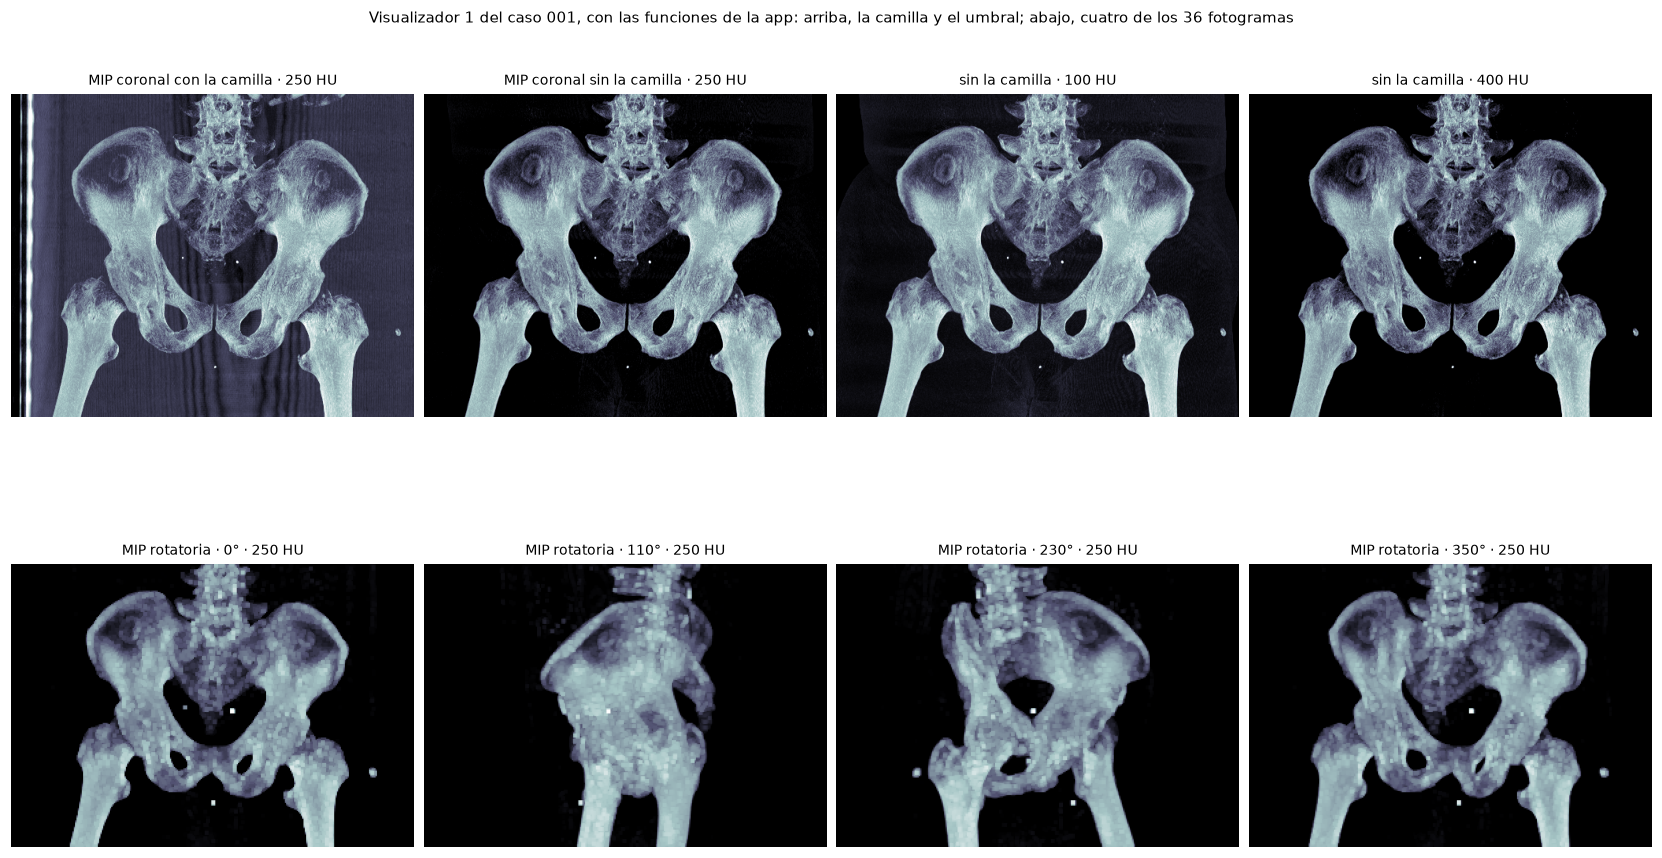

Quitar la camilla cambia el 55% de los píxeles de la MIP coronal · rotación de 36 fotogramas de 212×302 px en 1.8 s
Visualizador 3: 8 mallas, 21,674 vértices


In [98]:
CASO_V1 = "001"                                 # un paciente con la camilla bien visible
vol_crudo = app_pre.orientar(app_pre.leer(IMAGES / f"{CASO_V1}.mha"))
nativo, esp_nativo = sitk.GetArrayFromImage(vol_crudo).astype(np.int16), vol_crudo.GetSpacing()[::-1]
for t in (100, 250, 400, 700):          # umbralizar y proyectar conmutan
    assert np.array_equal(np.maximum(nativo, t).max(axis=1), np.maximum(nativo.max(axis=1), t))
sin_camilla = app_visual.aislar_paciente(nativo)
ventana = lambda p, t: np.clip((p.astype(np.float32) - t) / (app_visual.HU_MAX - t), 0, 1)  # noqa: E731
coronal = {"con la camilla": nativo.max(axis=1)[::-1], "sin la camilla": sin_camilla.max(axis=1)[::-1]}
cambio = np.mean(np.abs(ventana(coronal["con la camilla"], 250) - ventana(coronal["sin la camilla"], 250)) > 0.05)
t0 = time.perf_counter()
fotogramas, angulos = app_visual.rotacion_mip(nativo, esp_nativo, max_lado=256, dispositivo=DISPOSITIVO)
t_mip = time.perf_counter() - t0
mallas_app = app_visual.mallas(vol_app, app_pipeline.fragmentos_del_caso(vol_app))

aspecto = esp_nativo[0] / esp_nativo[2]
fig, axs = plt.subplots(2, 4, figsize=(15, 8.4), layout="constrained")
for ax, (rotulo, p) in zip(axs[0, :2], coronal.items()):
    ax.imshow(ventana(p, 250), cmap="bone", aspect=aspecto)
    ax.set_title(f"MIP coronal {rotulo} · 250 HU", fontsize=9)
for ax, t in zip(axs[0, 2:], (100, 400)):
    ax.imshow(ventana(coronal["sin la camilla"], t), cmap="bone", aspect=aspecto)
    ax.set_title(f"sin la camilla · {t} HU", fontsize=9)
for ax, i in zip(axs[1], np.linspace(0, len(angulos) - 1, 4).astype(int)):
    ax.imshow(ventana(fotogramas[i], 250), cmap="bone")
    ax.set_title(f"MIP rotatoria · {angulos[i]:.0f}° · 250 HU", fontsize=9)
for ax in axs.flat:
    ax.axis("off")
fig.suptitle(f"Visualizador 1 del caso {CASO_V1}, con las funciones de la app: arriba, la camilla y el umbral; abajo, "
             f"cuatro de los {len(angulos)} fotogramas", fontsize=10)
plt.show()
print(f"Quitar la camilla cambia el {cambio:.0%} de los píxeles de la MIP coronal · rotación de {len(angulos)} fotogramas "
      f"de {fotogramas.shape[1]}×{fotogramas.shape[2]} px en {t_mip:.1f} s")
print(f"Visualizador 3: {len(mallas_app)} mallas, {sum(len(m['x']) for m in mallas_app):,} vértices")
pd.DataFrame([{"fragmento": m["nombre"], "vértices": len(m["x"]), "triángulos": len(m["i"]), "color": m["color"]}
              for m in mallas_app]).set_index("fragmento")
del nativo, sin_camilla, vol_crudo